In [ ]:
!pip install numpy

# Identification des valeurs manquantes

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
import io
import json

# ─── 1. Upload des fichiers ───────────────────────────────────────────────────
print("📁 Sélectionne tes fichiers Excel, CSV ou JSON :")
uploaded = files.upload()

# Dictionnaire qui contient tous les DataFrames
dfs = {}

# ─── 2. Lecture de chaque fichier ─────────────────────────────────────────────
for filename, contenu in uploaded.items():

    print(f"\n📂 Chargement : {filename}")

    if filename.lower().endswith(".csv"):
        df = pd.read_csv(io.BytesIO(contenu))

    elif filename.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(io.BytesIO(contenu))

    elif filename.lower().endswith(".json"):

        data = json.loads(contenu.decode("utf-8"))

        # JSON = liste
        if isinstance(data, list):

            if all(isinstance(x, dict) for x in data):
                df = pd.json_normalize(data)
            else:
                df = pd.DataFrame(data, columns=["value"])

        # JSON = dictionnaire
        elif isinstance(data, dict):

            list_found = False

            for key, value in data.items():

                if isinstance(value, list) and len(value) > 0:

                    # Liste de dictionnaires
                    if all(isinstance(x, dict) for x in value):
                        df = pd.json_normalize(value)
                        print(f"📌 Données trouvées dans la clé : '{key}'")
                        list_found = True
                        break

            # Aucun tableau de dictionnaires trouvé
            if not list_found:
                df = pd.json_normalize(data)

        else:
            raise ValueError(f"❌ Structure JSON non supportée : {filename}")

    else:
        raise ValueError(f"❌ Format non supporté : {filename}")

    # ─── 3. Ajouter le DataFrame au dictionnaire ──────────────────────────────
    dfs[filename] = df

    print(f"✅ {filename} chargé")
    print(f"📊 Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")


# ─── 4. Parcourir tous les DataFrames ─────────────────────────────────────────
print("\n" + "="*60)
print("📋 COLONNES DE TOUS LES FICHIERS")
print("="*60)

for filename, df in dfs.items():

    print(f"\n📁 {filename}")
    print(f"   Nombre de lignes : {df.shape[0]}")
    print(f"   Nombre de colonnes : {df.shape[1]}")
    print(f"   Colonnes :")

    for column in df.columns:
        print(f"      - {column}")

📁 Sélectionne tes fichiers Excel, CSV ou JSON :


Saving classement_arwu_shanghai.csv to classement_arwu_shanghai (1).csv
Saving classement_qs_monde.csv to classement_qs_monde (1).csv
Saving classement_the_disciplines.csv to classement_the_disciplines (1).csv
Saving classement_the_impact_odd.csv to classement_the_impact_odd (1).csv
Saving classement_the_monde.csv to classement_the_monde (1).csv
Saving controle_qualite.csv to controle_qualite (1).csv
Saving disciplines_par_universite.csv to disciplines_par_universite (1).csv
Saving donnees_consolidees.csv to donnees_consolidees (1).csv
Saving donnees_durabilite.xlsx to donnees_durabilite (1).xlsx
Saving rapports_annuels.csv to rapports_annuels (1).csv
Saving rapports_annuels_details.json to rapports_annuels_details (1).json
Saving universites.csv to universites (1).csv

📂 Chargement : classement_arwu_shanghai (1).csv
✅ classement_arwu_shanghai (1).csv chargé
📊 Dimensions : 210 lignes × 6 colonnes

📂 Chargement : classement_qs_monde (1).csv
✅ classement_qs_monde (1).csv chargé
📊 Dimensi

In [ ]:
!pip install missingno

In [ ]:
!pip install matplotlib


📌 classement_arwu_shanghai (1).csv
Axes(0.125,0.11;0.698618x0.77)


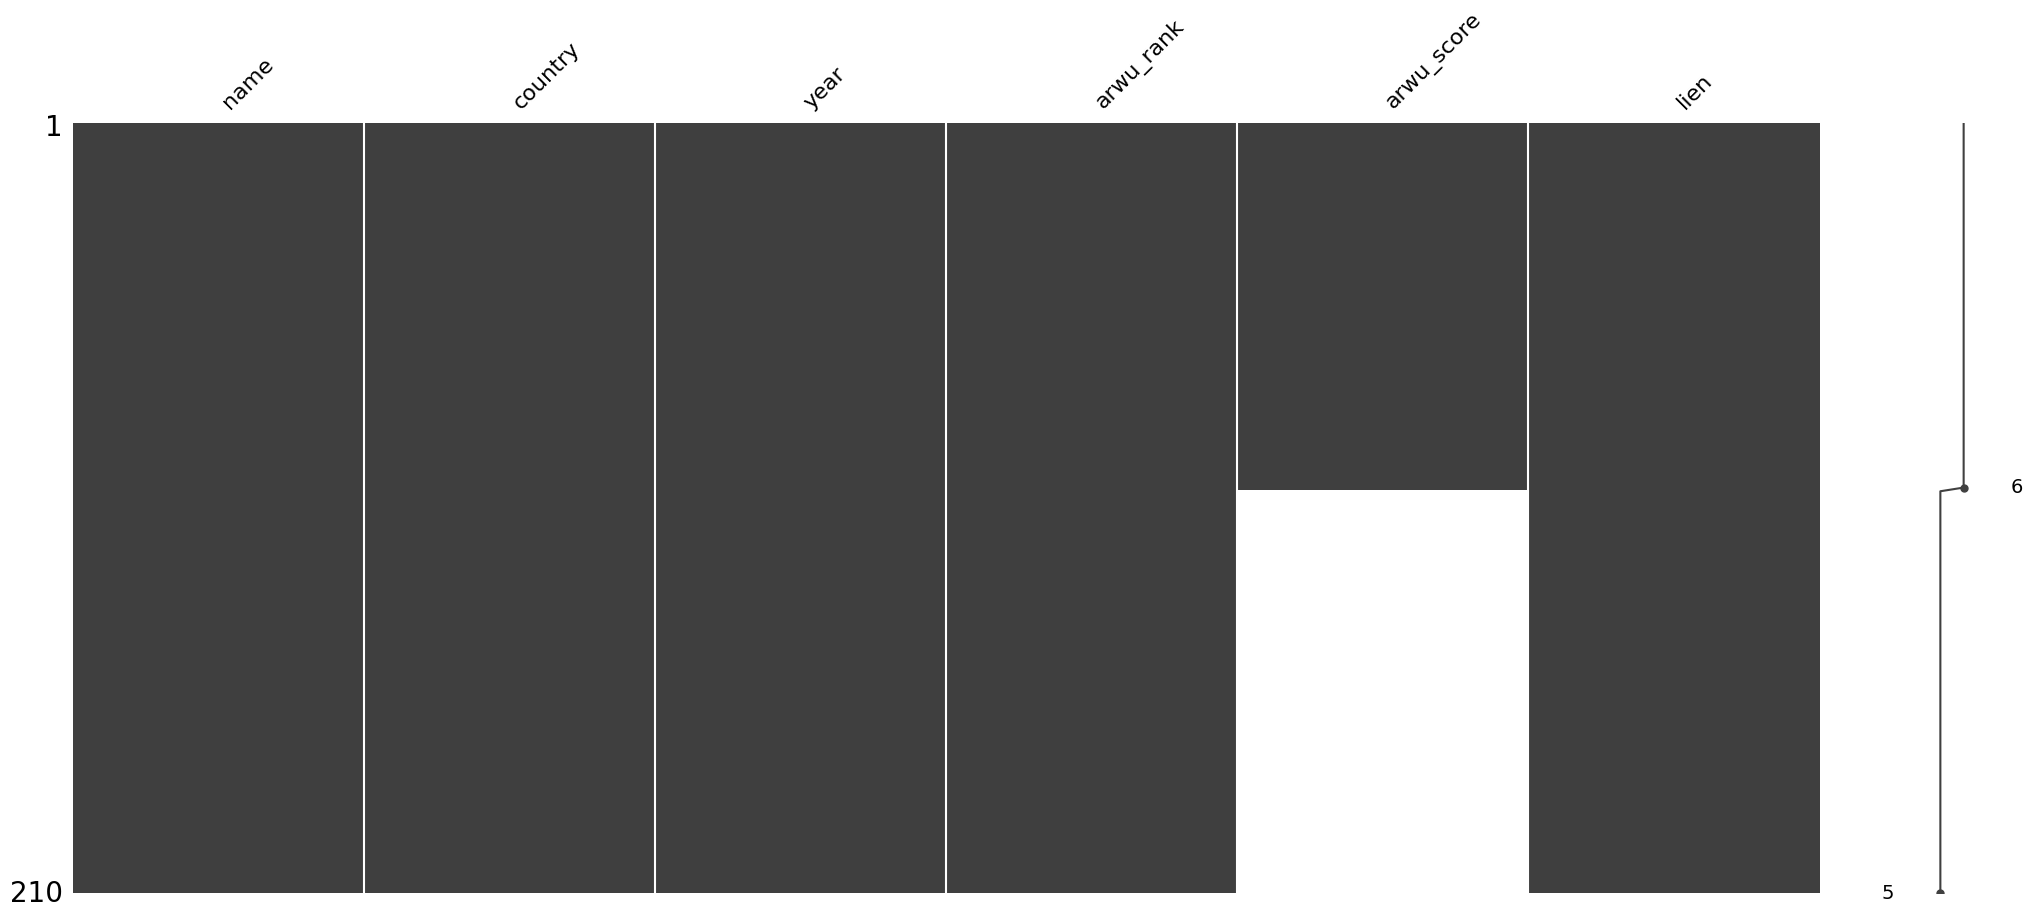


📌 classement_qs_monde (1).csv
Axes(0.125,0.11;0.698618x0.77)


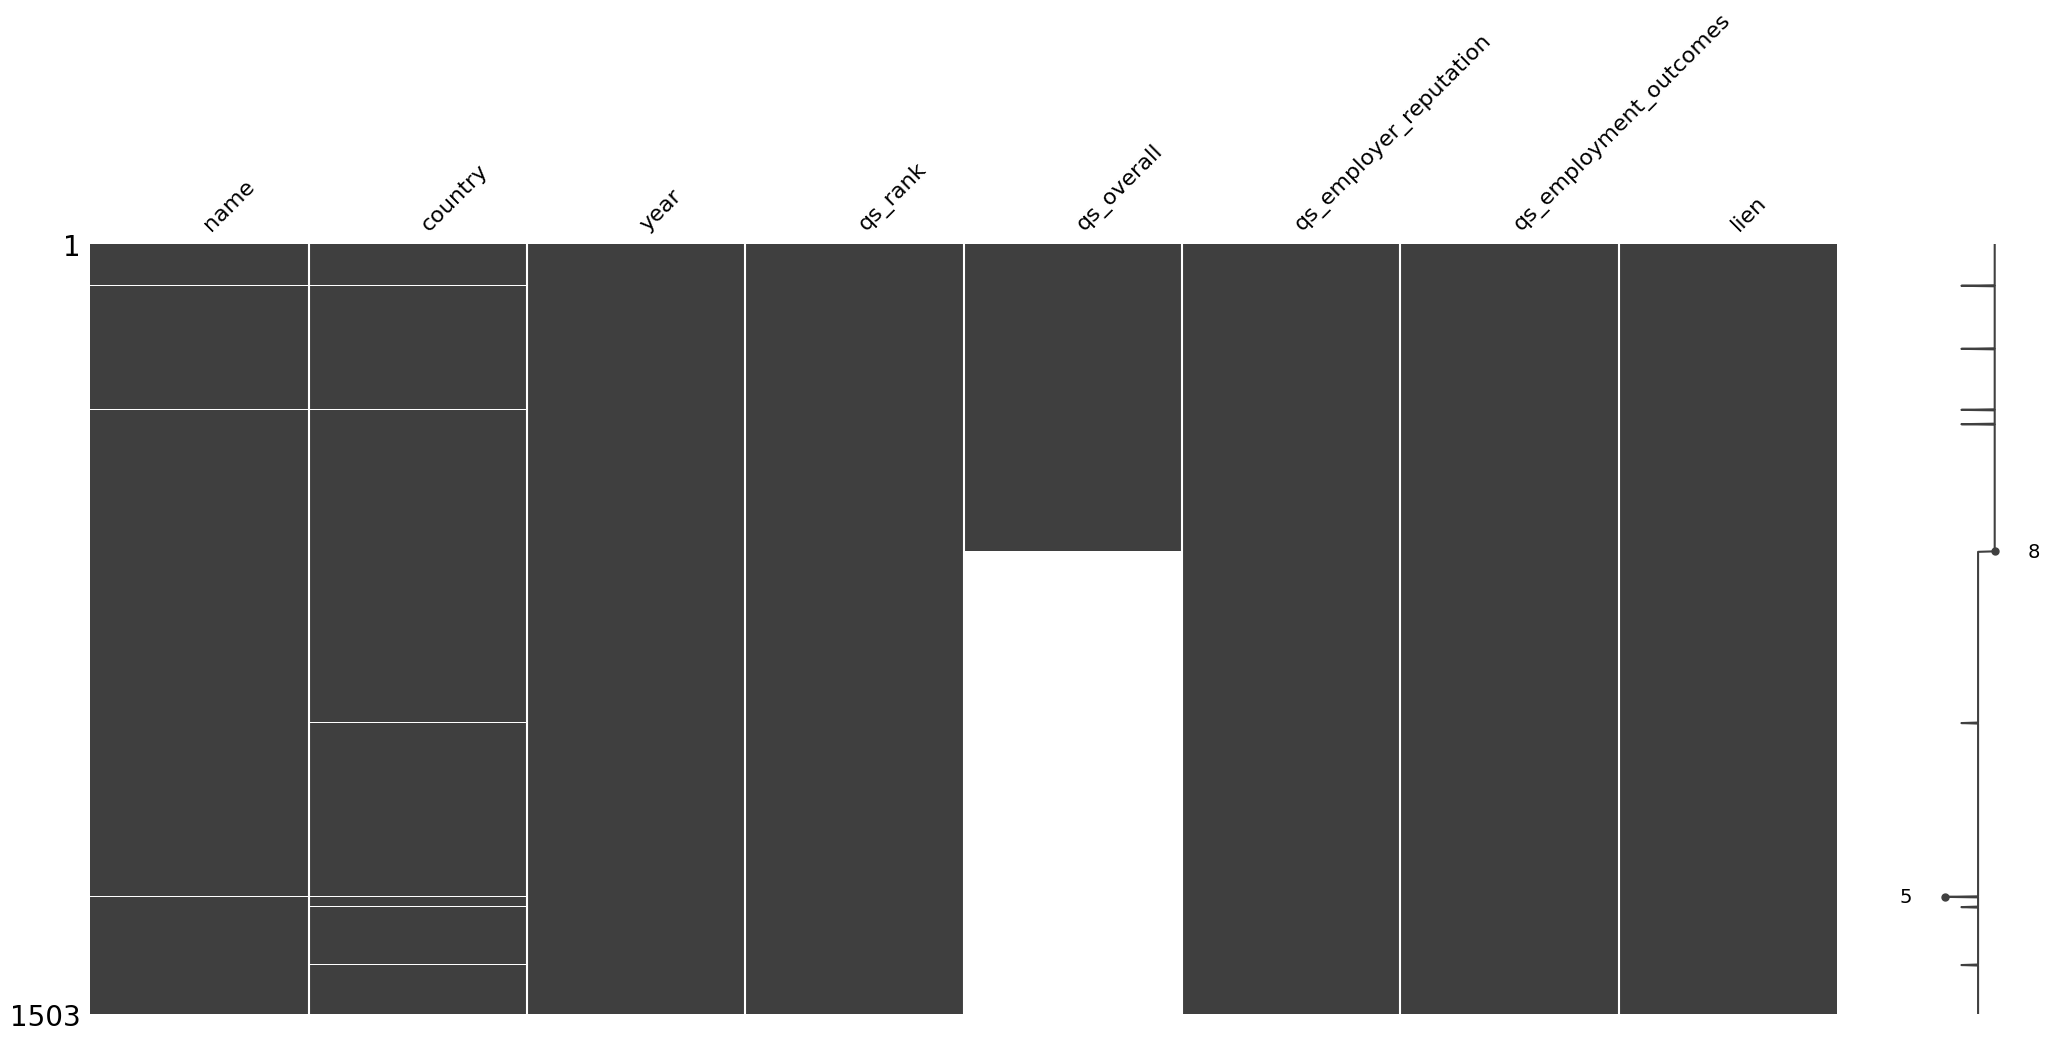


📌 classement_the_disciplines (1).csv
Axes(0.125,0.11;0.698618x0.77)


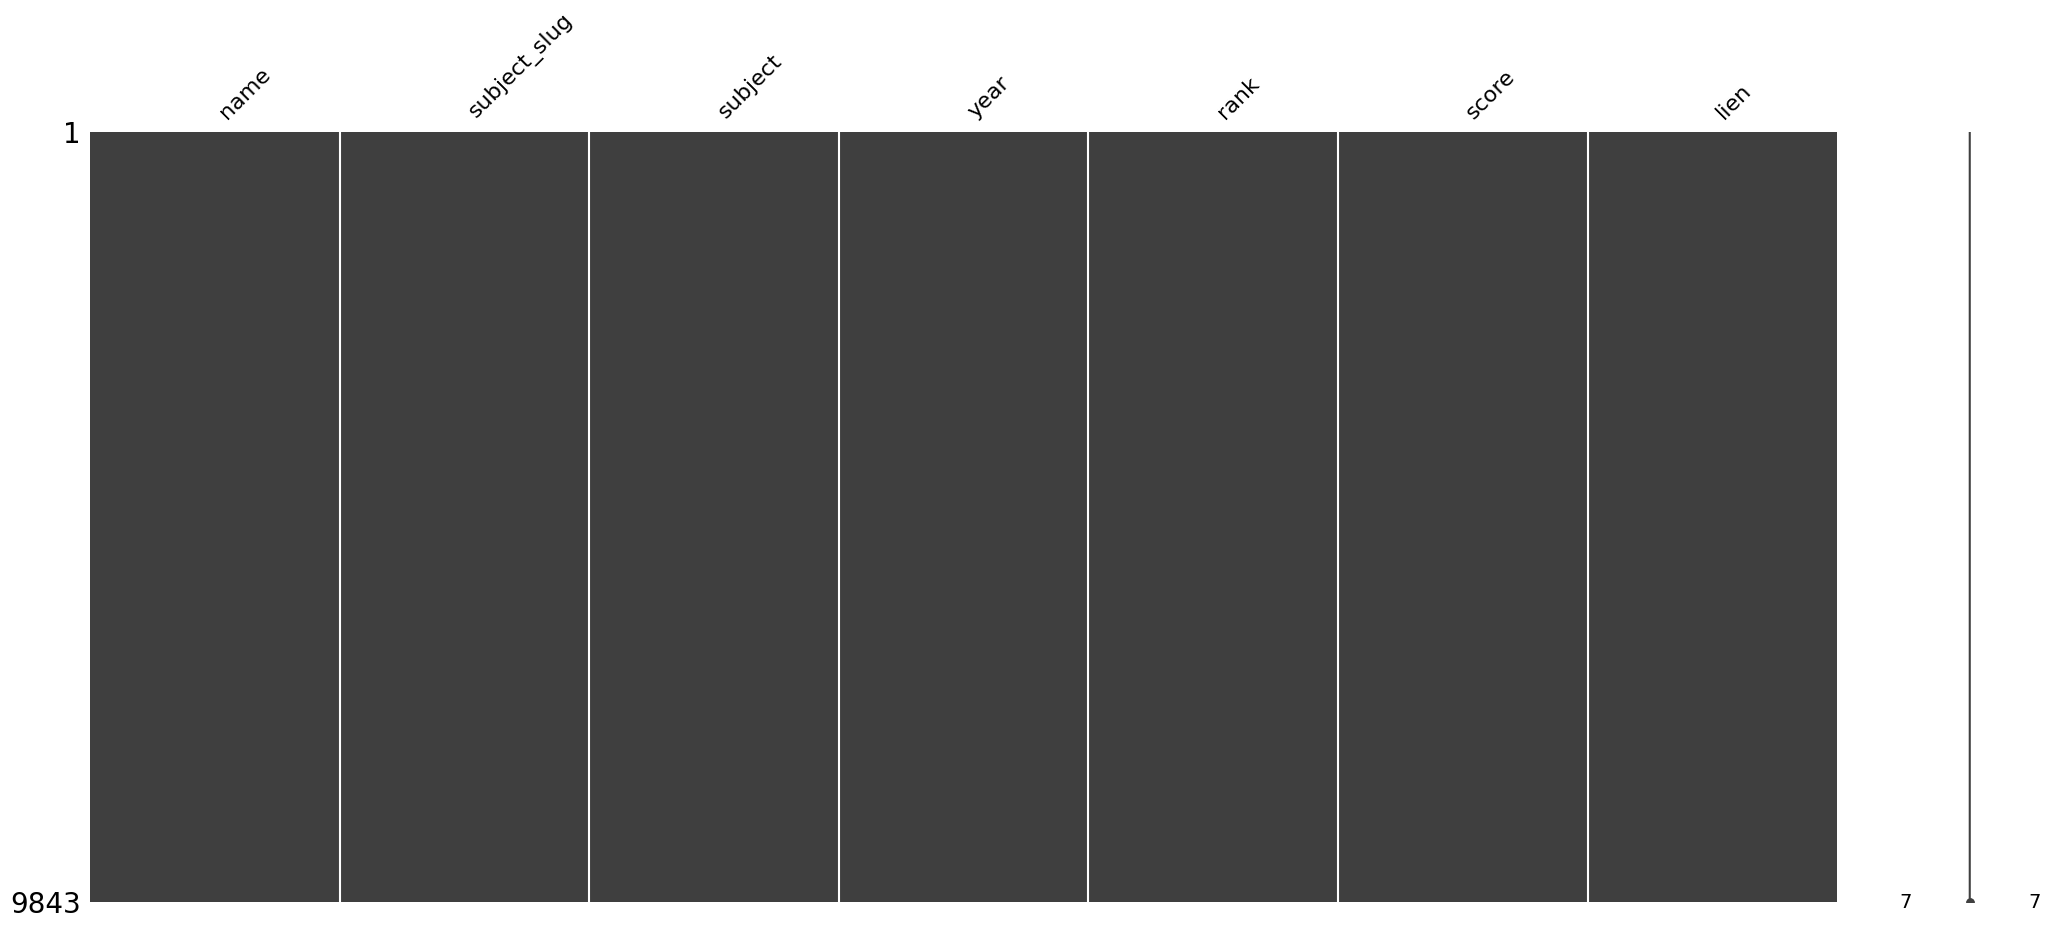


📌 classement_the_impact_odd (1).csv
Axes(0.125,0.11;0.698618x0.77)


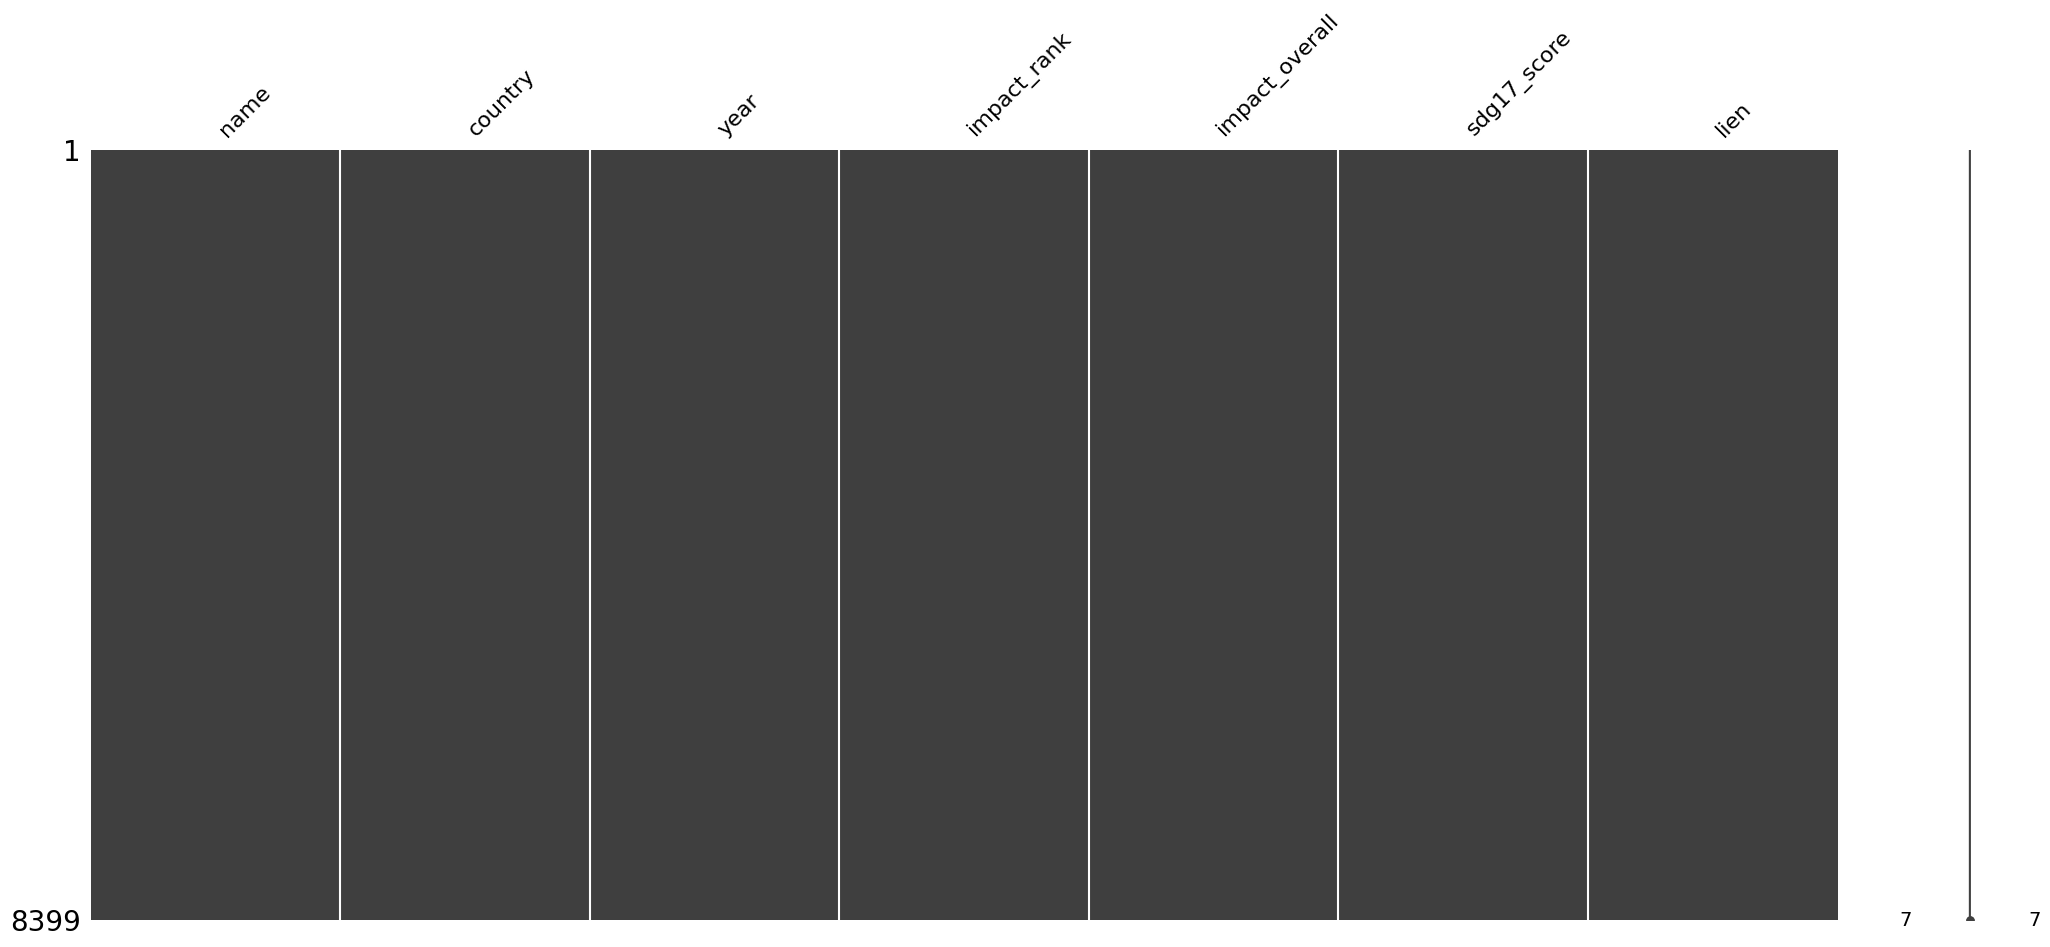


📌 classement_the_monde (1).csv
Axes(0.125,0.11;0.698618x0.77)


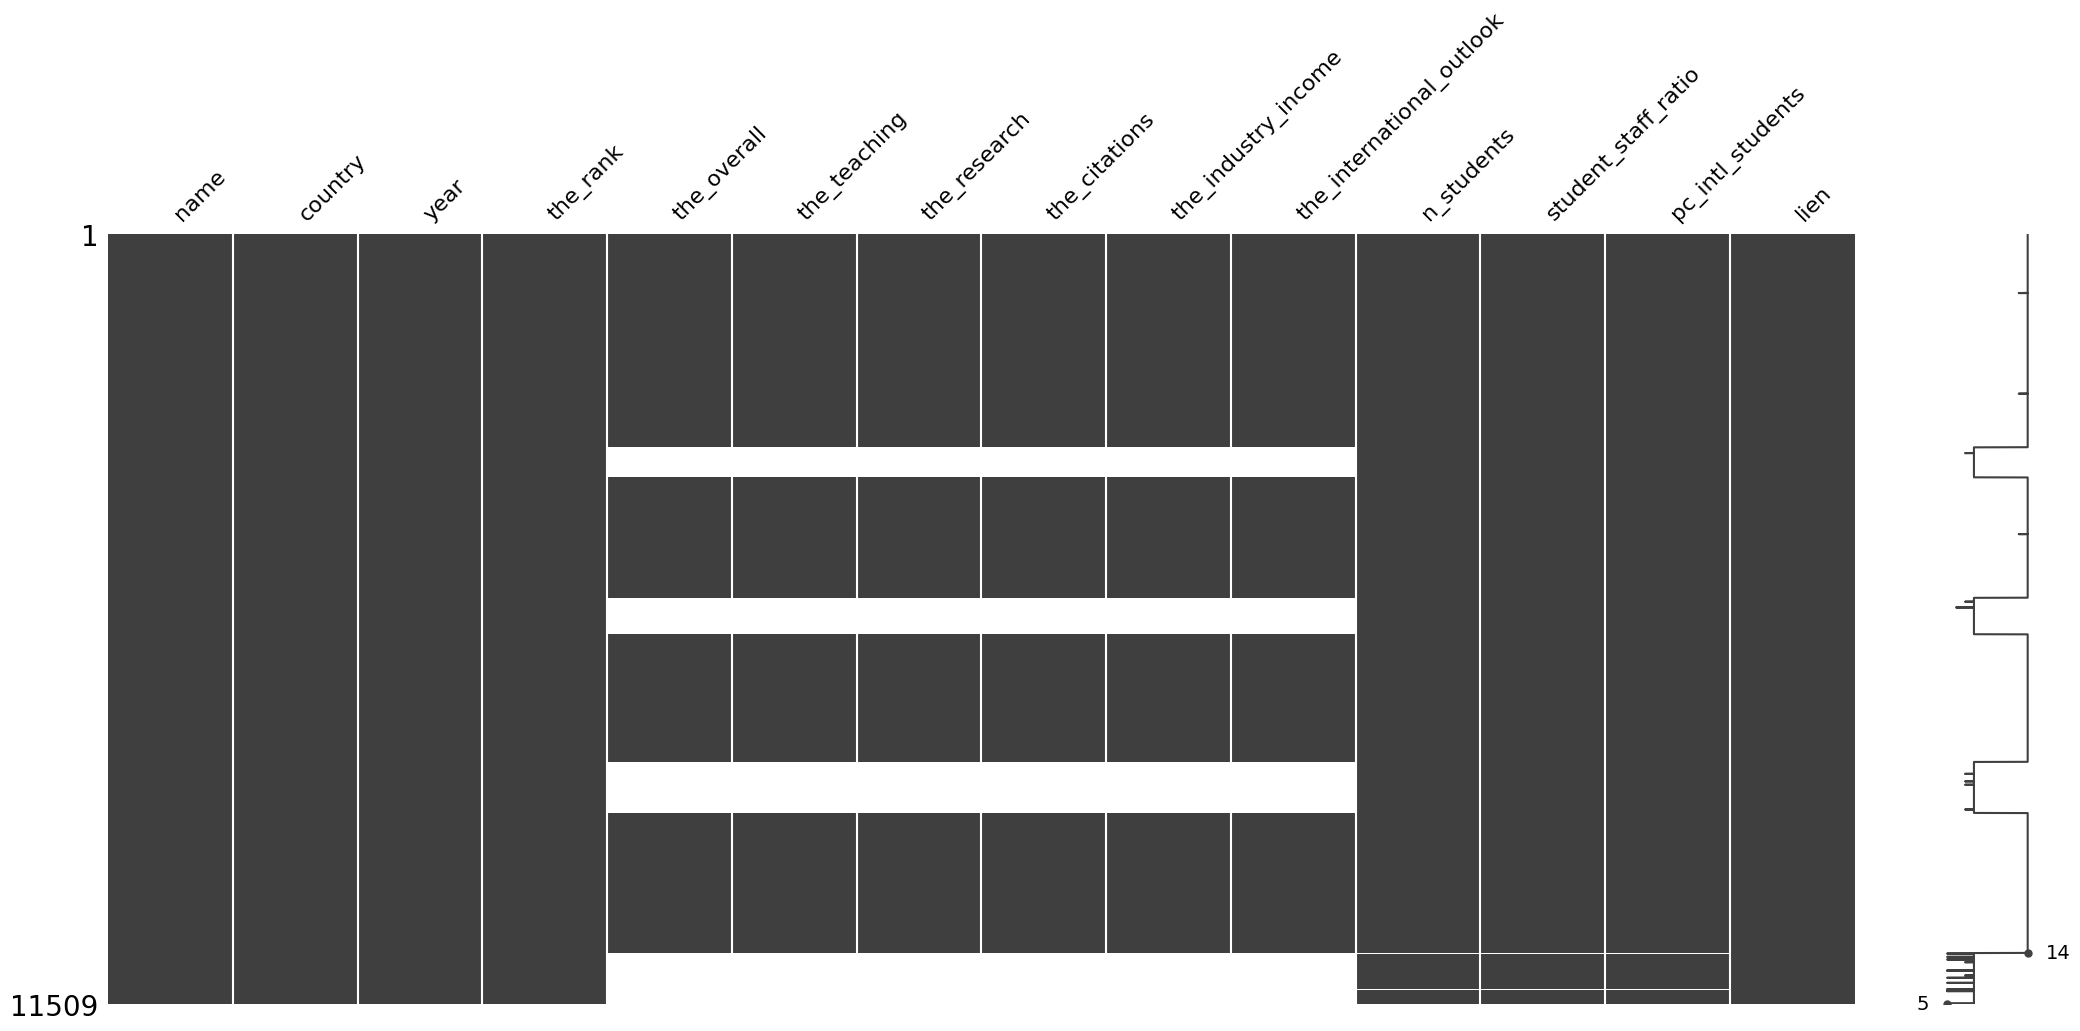


📌 controle_qualite (1).csv
Axes(0.125,0.11;0.698618x0.77)


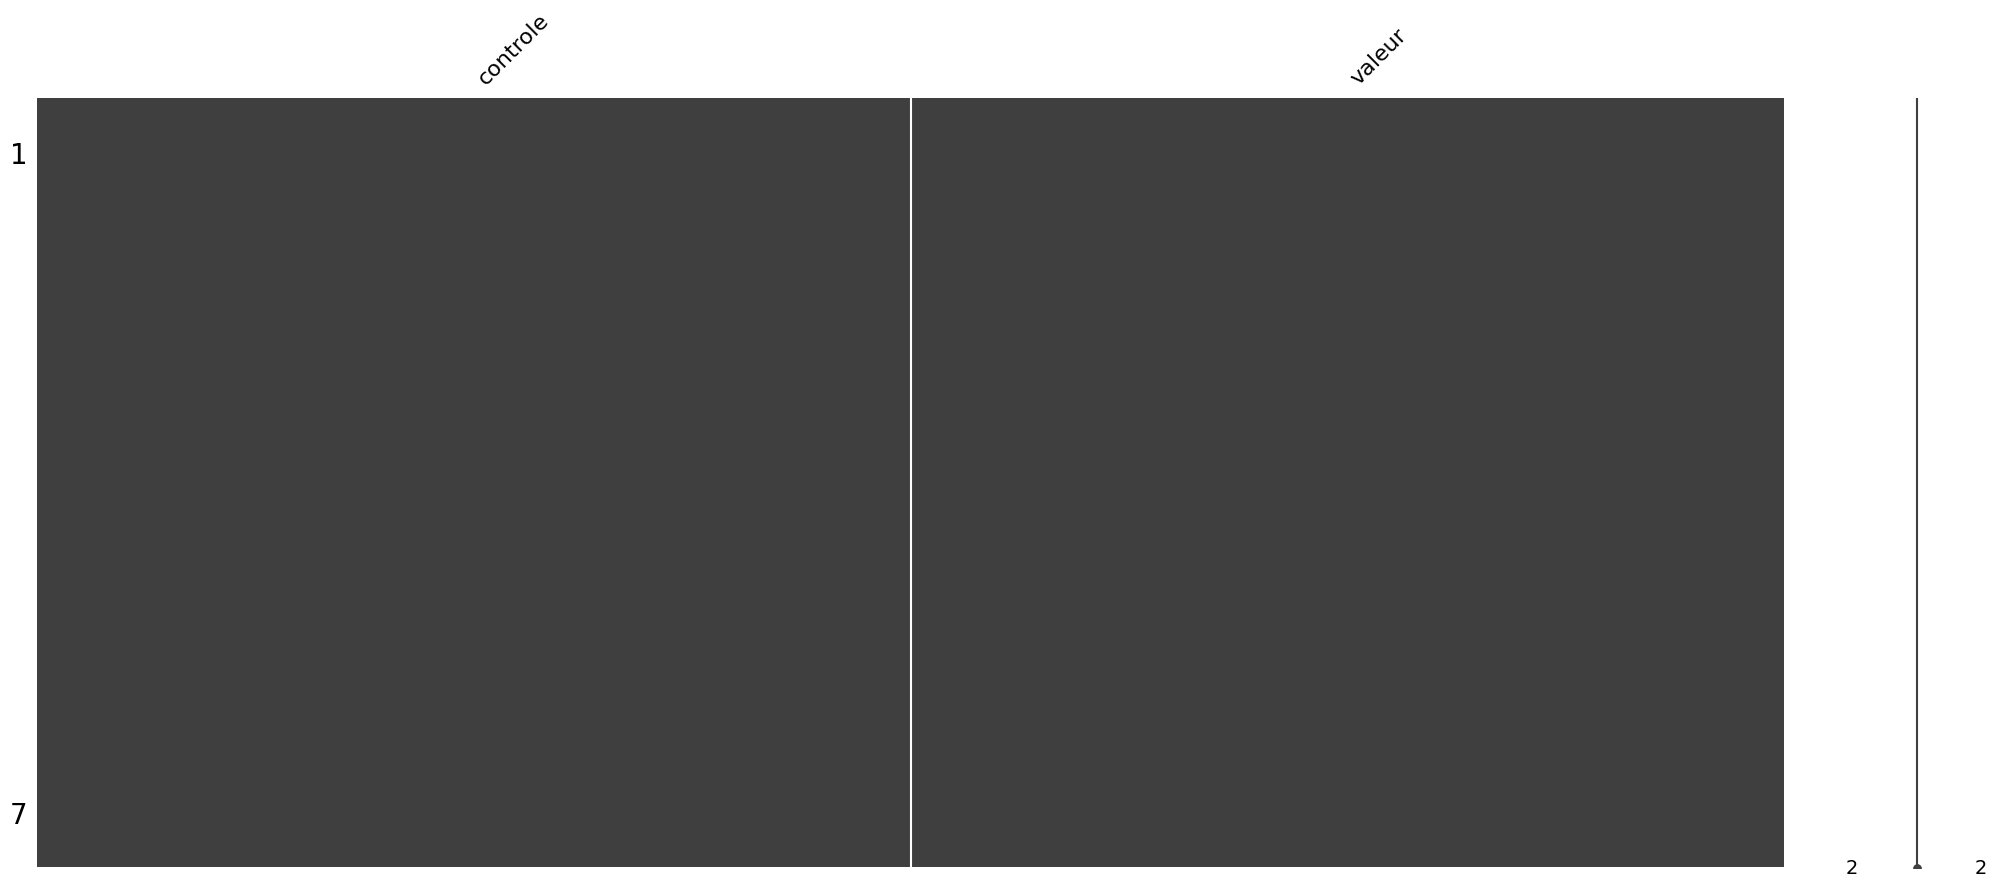


📌 disciplines_par_universite (1).csv
Axes(0.125,0.11;0.698618x0.77)


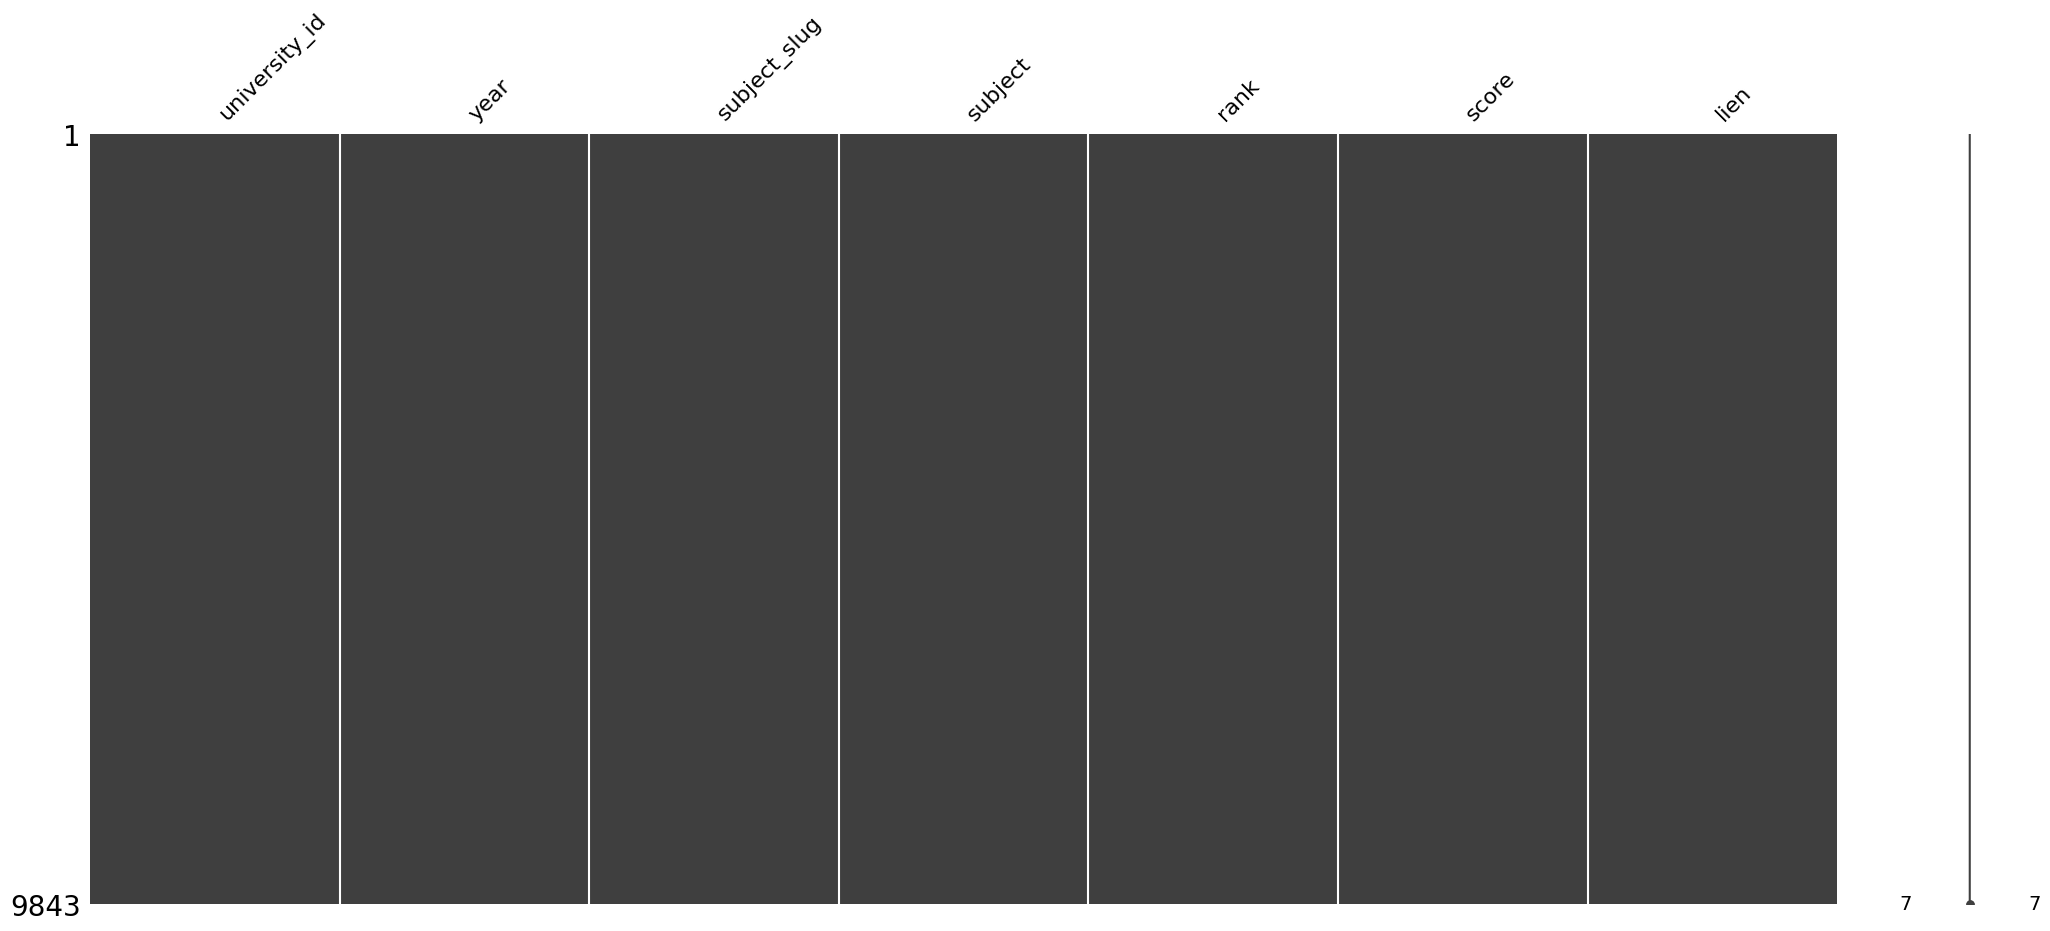


📌 donnees_consolidees (1).csv
Axes(0.125,0.11;0.698618x0.77)


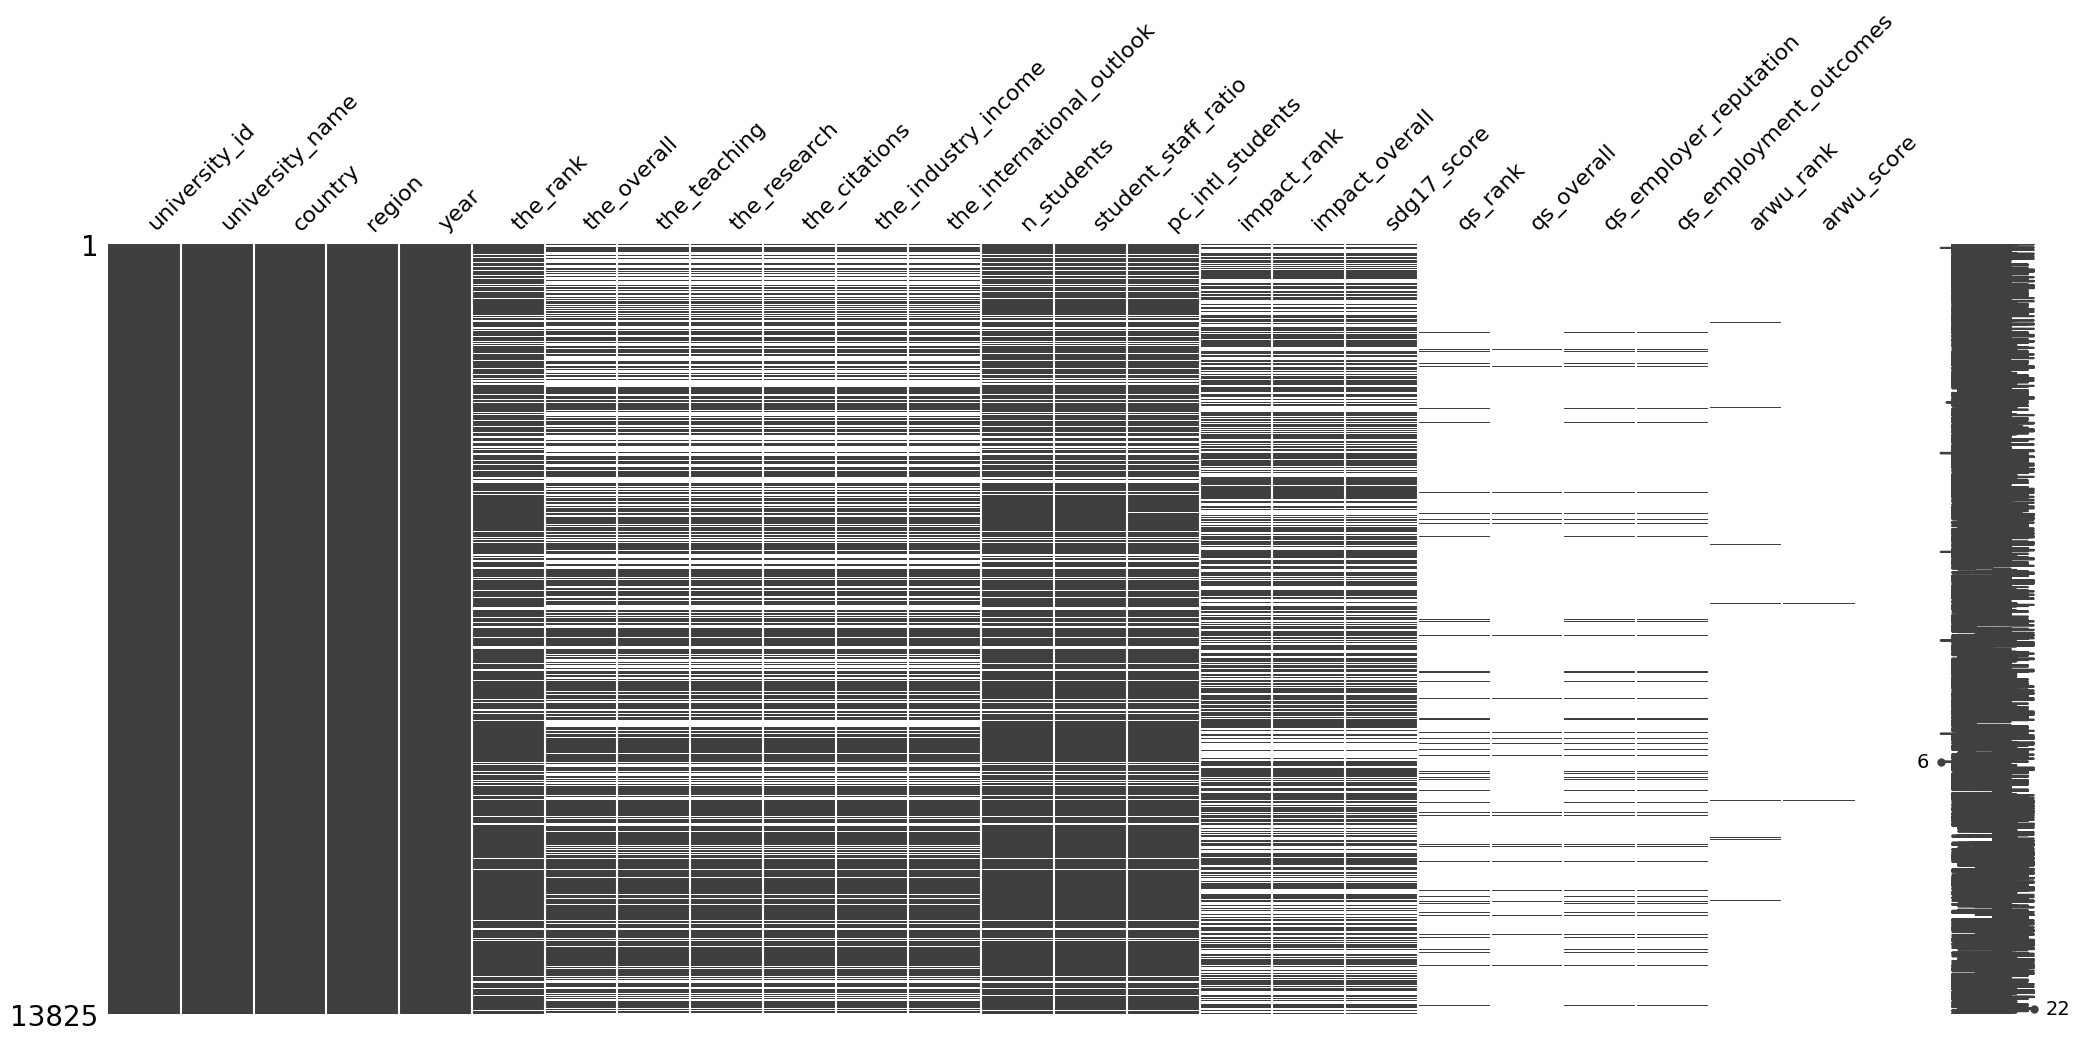


📌 donnees_durabilite (1).xlsx
Axes(0.125,0.11;0.698618x0.77)


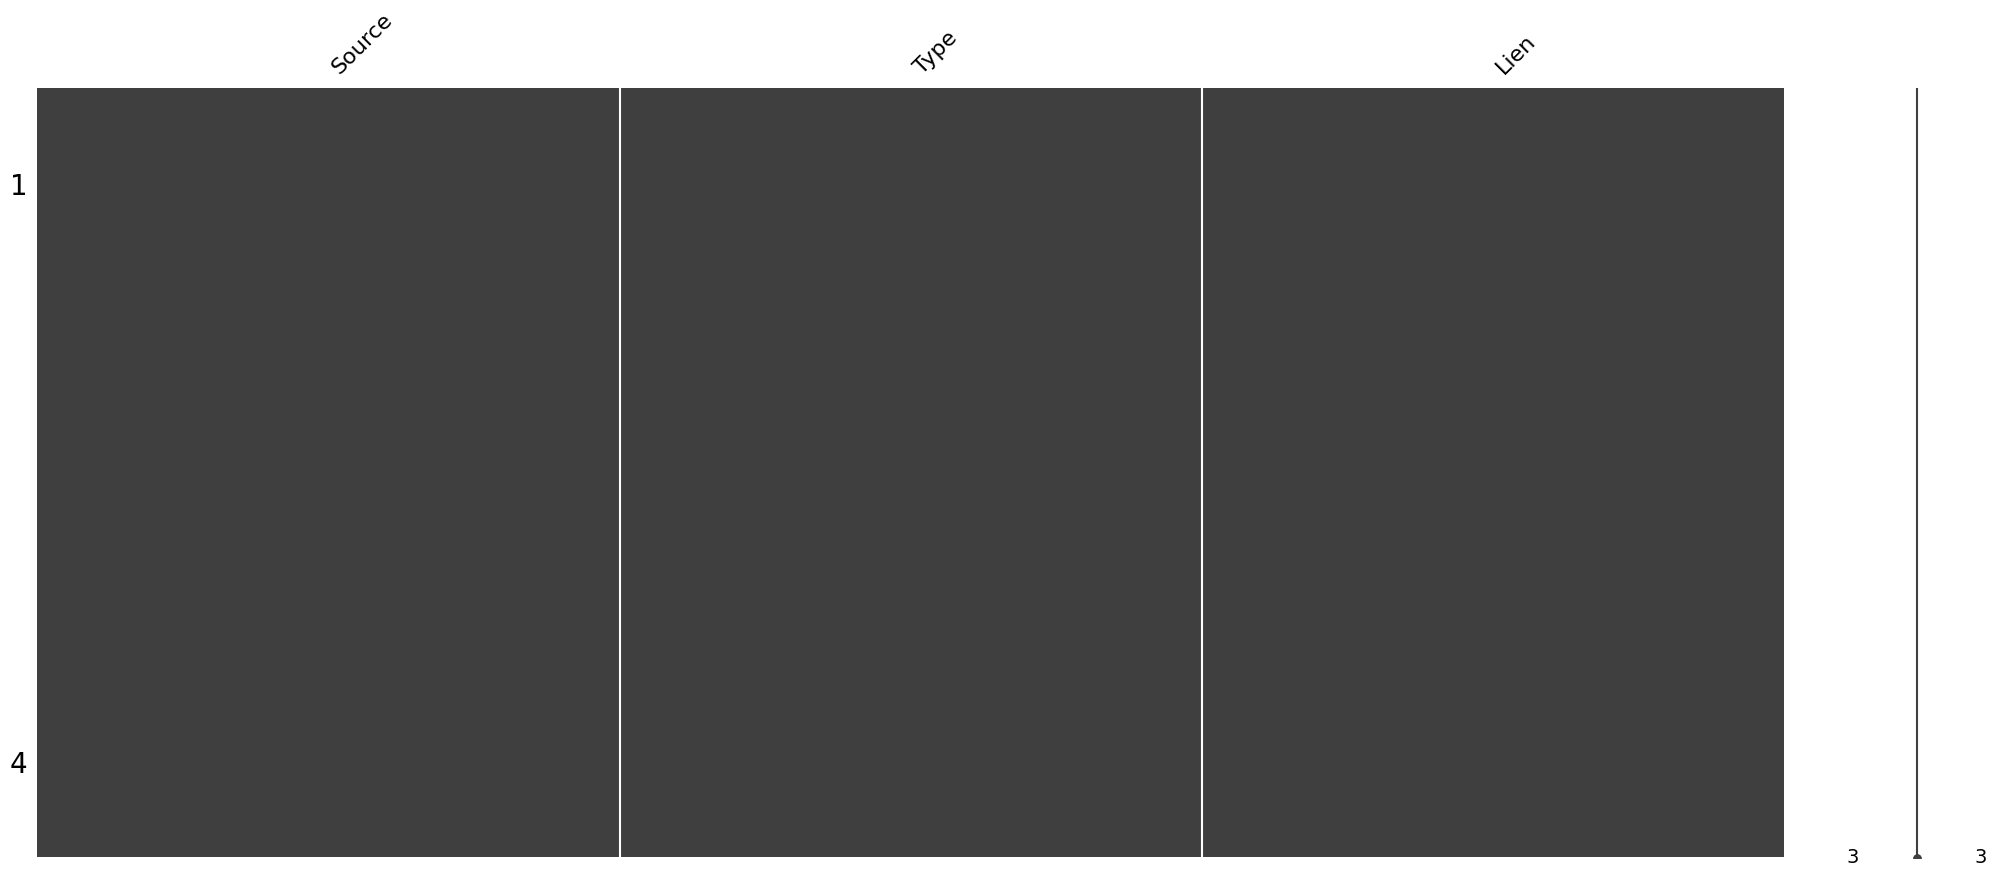


📌 rapports_annuels (1).csv
Axes(0.125,0.11;0.698618x0.77)


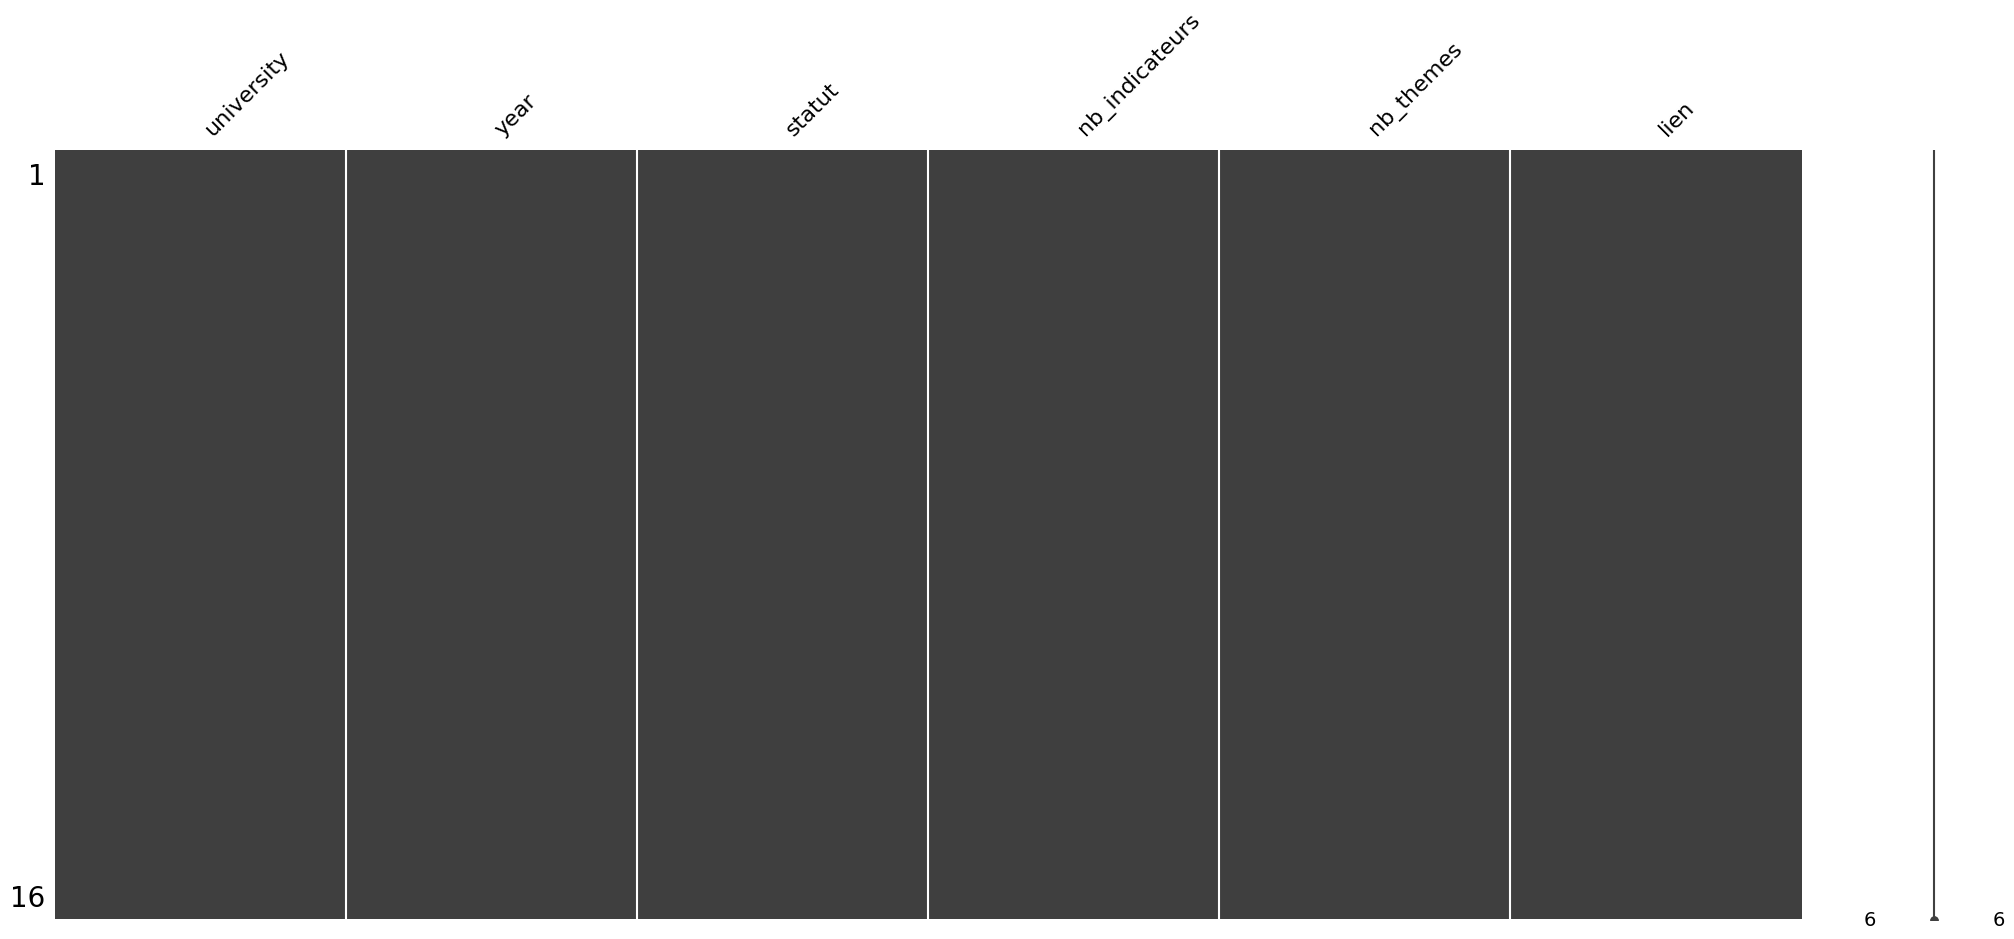


📌 rapports_annuels_details (1).json
Axes(0.125,0.11;0.698618x0.77)


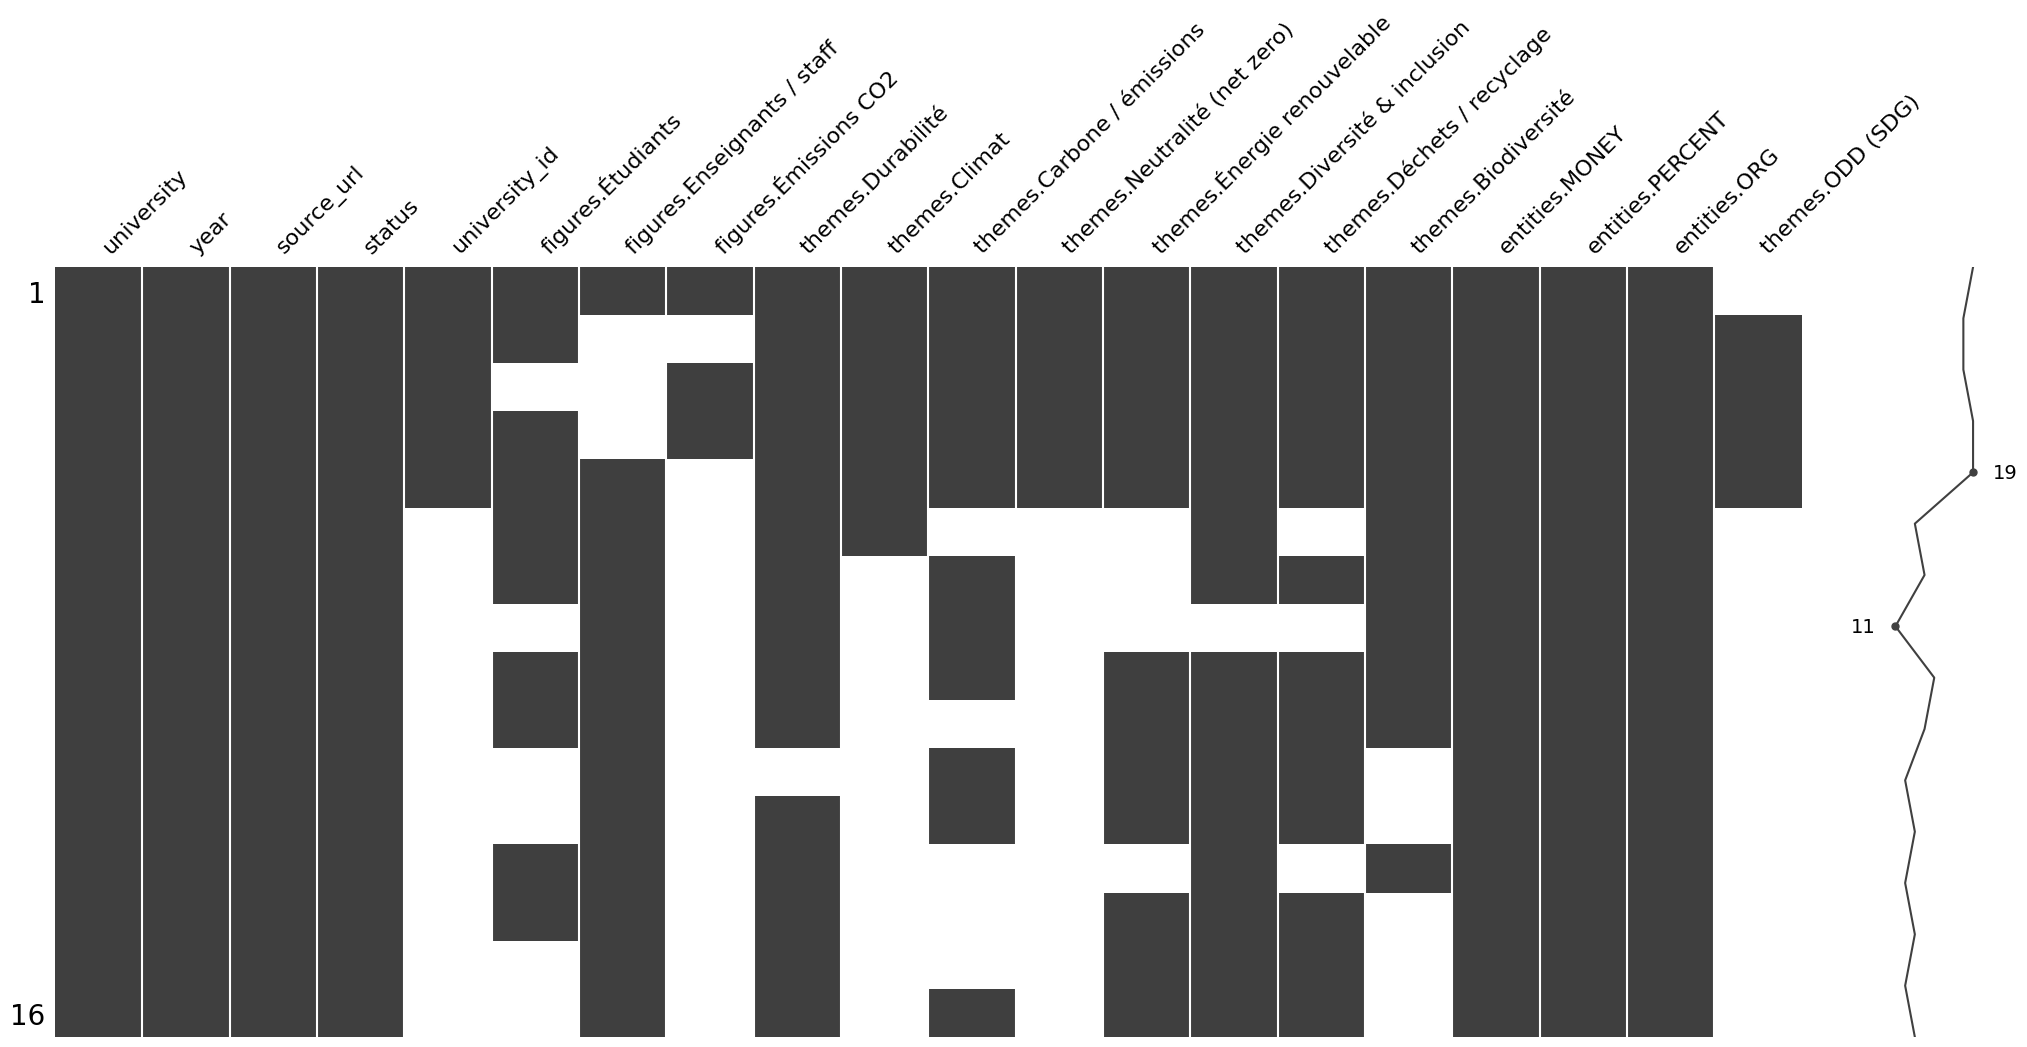


📌 universites (1).csv
Axes(0.125,0.11;0.698618x0.77)


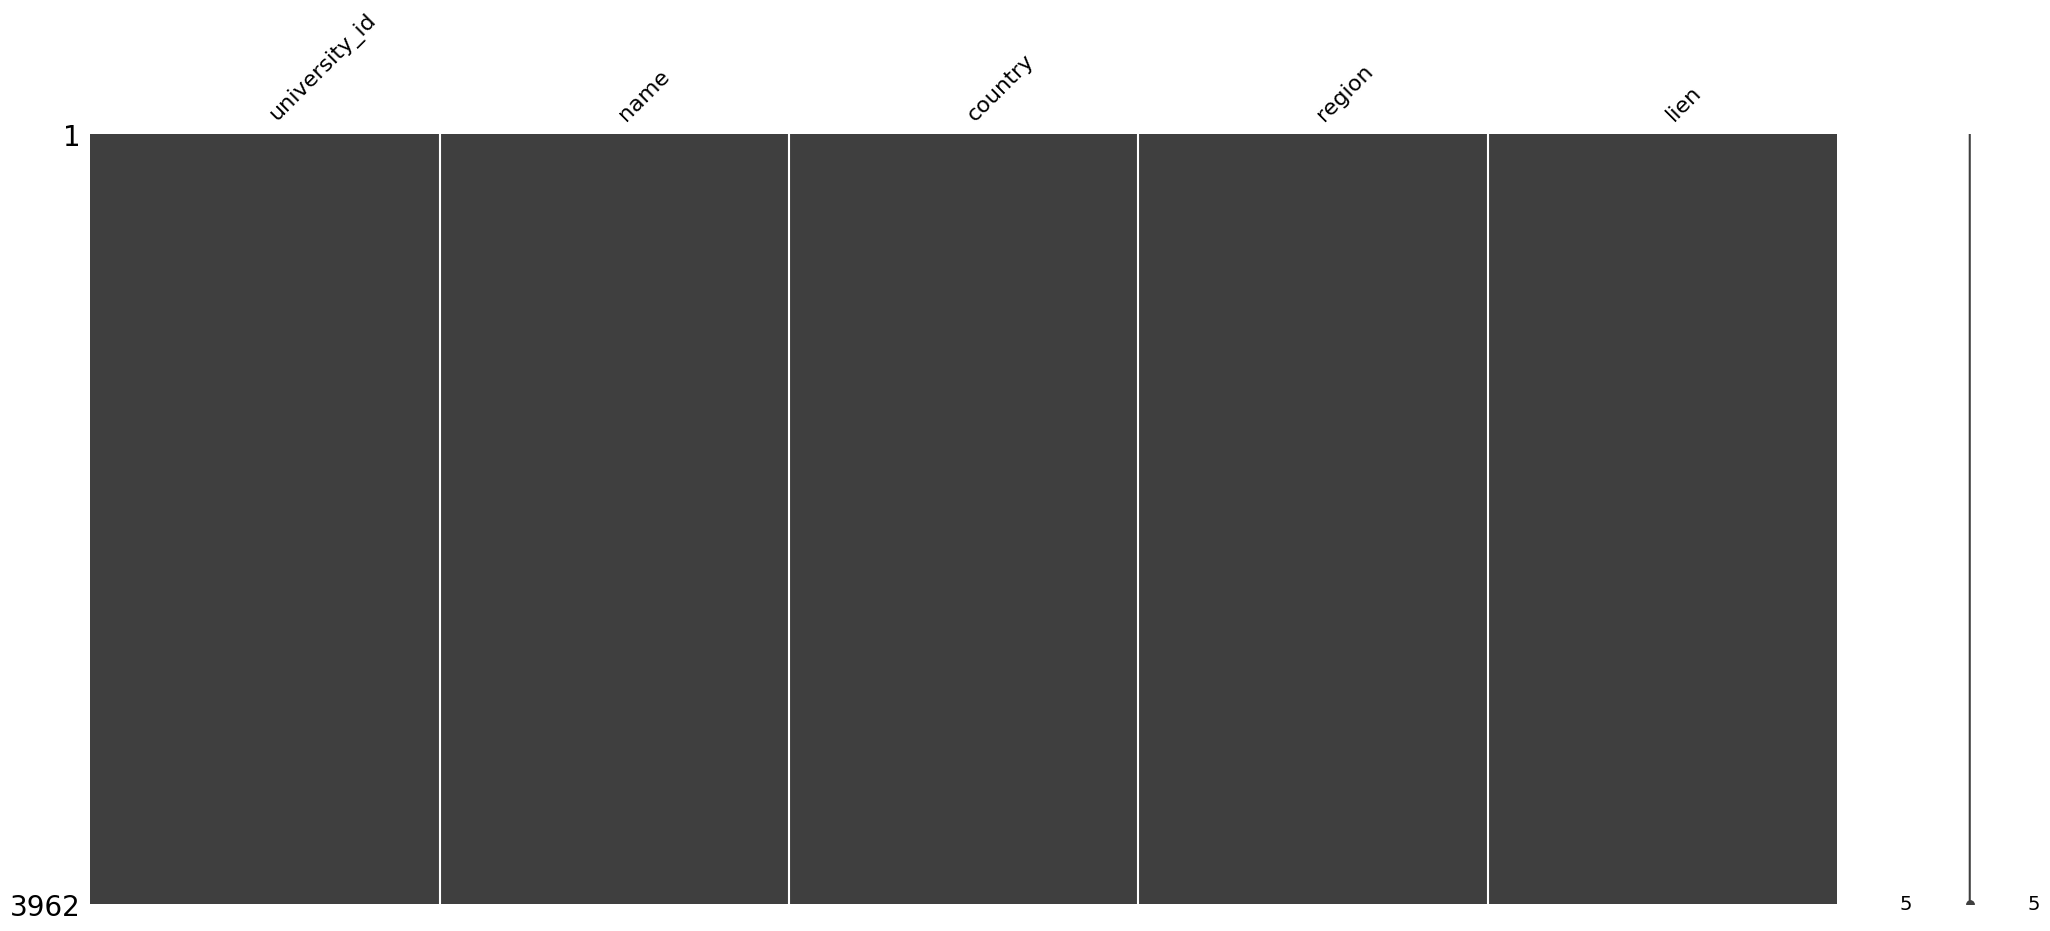

In [ ]:
# Visualiser les valeurs manquantes avec missingno
import matplotlib.pyplot as plt
import missingno as msno

# Parcourir tous les DataFrames
for name, dataframe in dfs.items():
    print(f"\n📌 {name}")
    print(msno.matrix(dataframe))
    plt.show()


📌 classement_arwu_shanghai (1).csv
Axes(0.125,0.11;0.775x0.77)


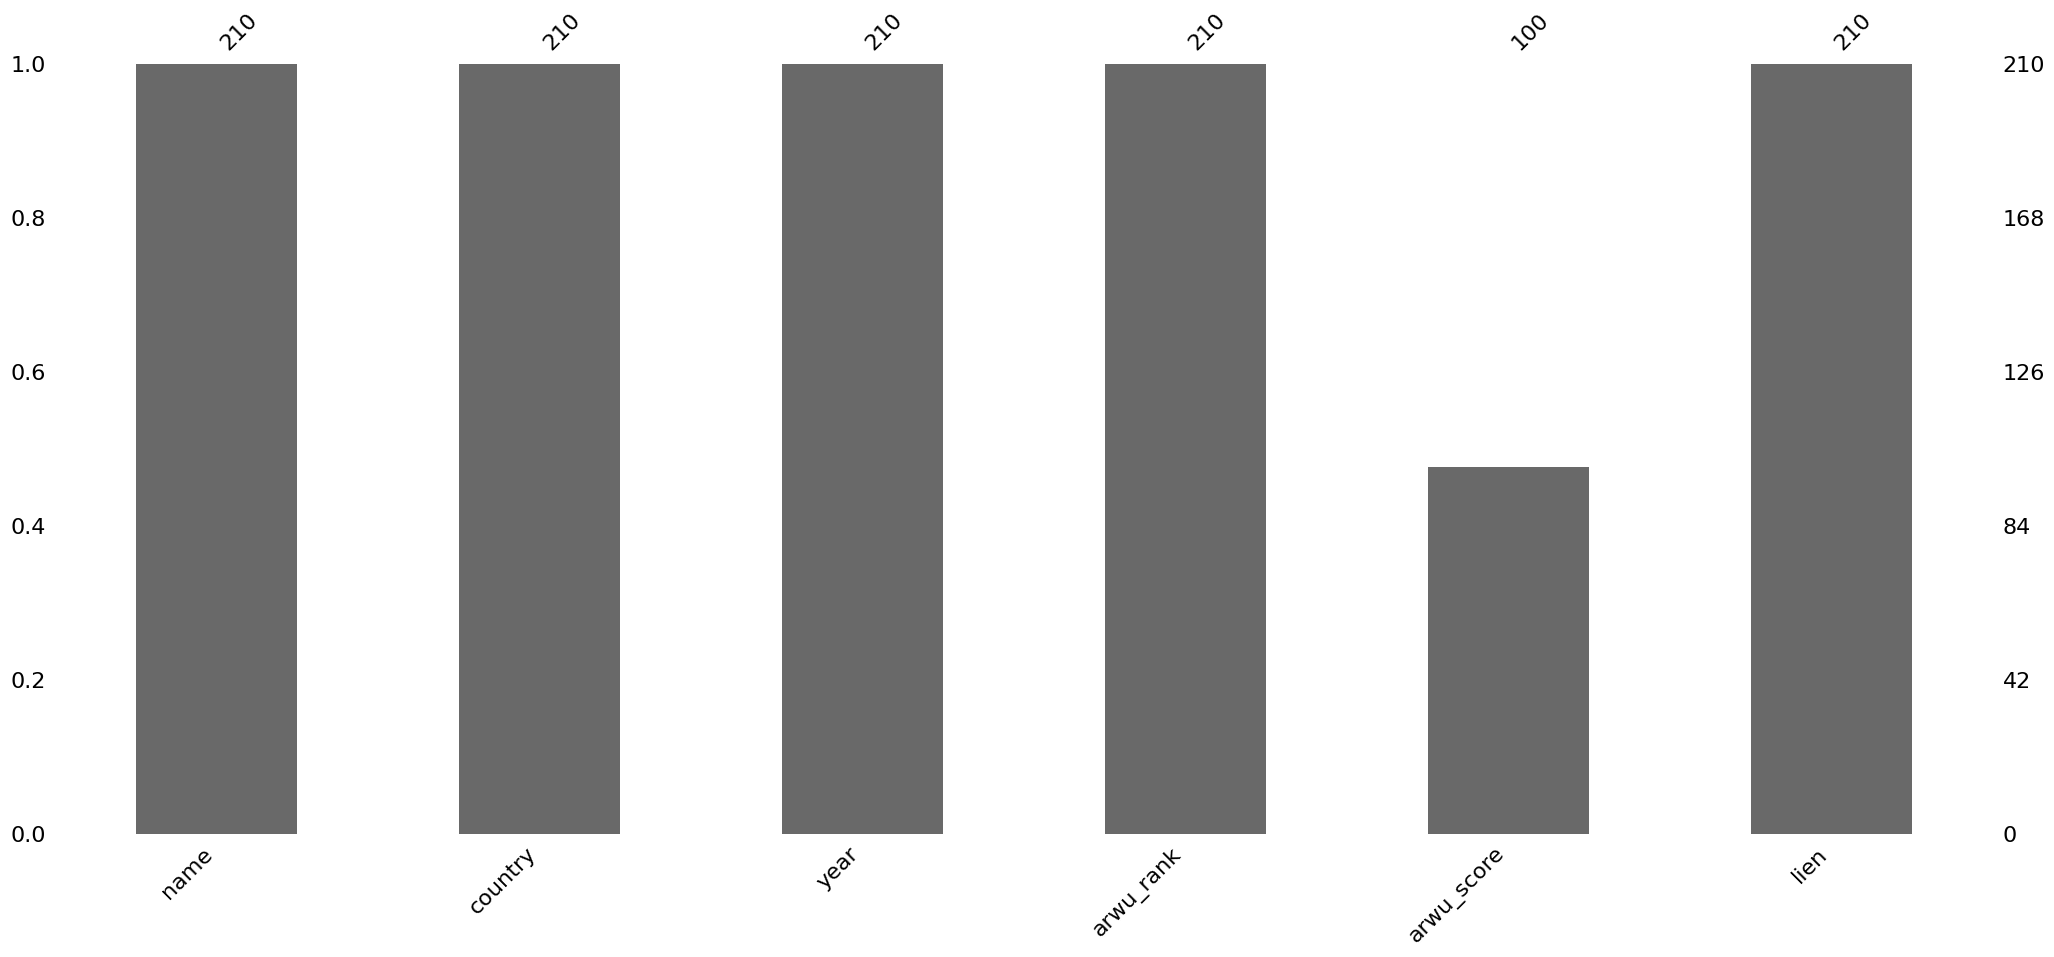


📌 classement_qs_monde (1).csv
Axes(0.125,0.11;0.775x0.77)


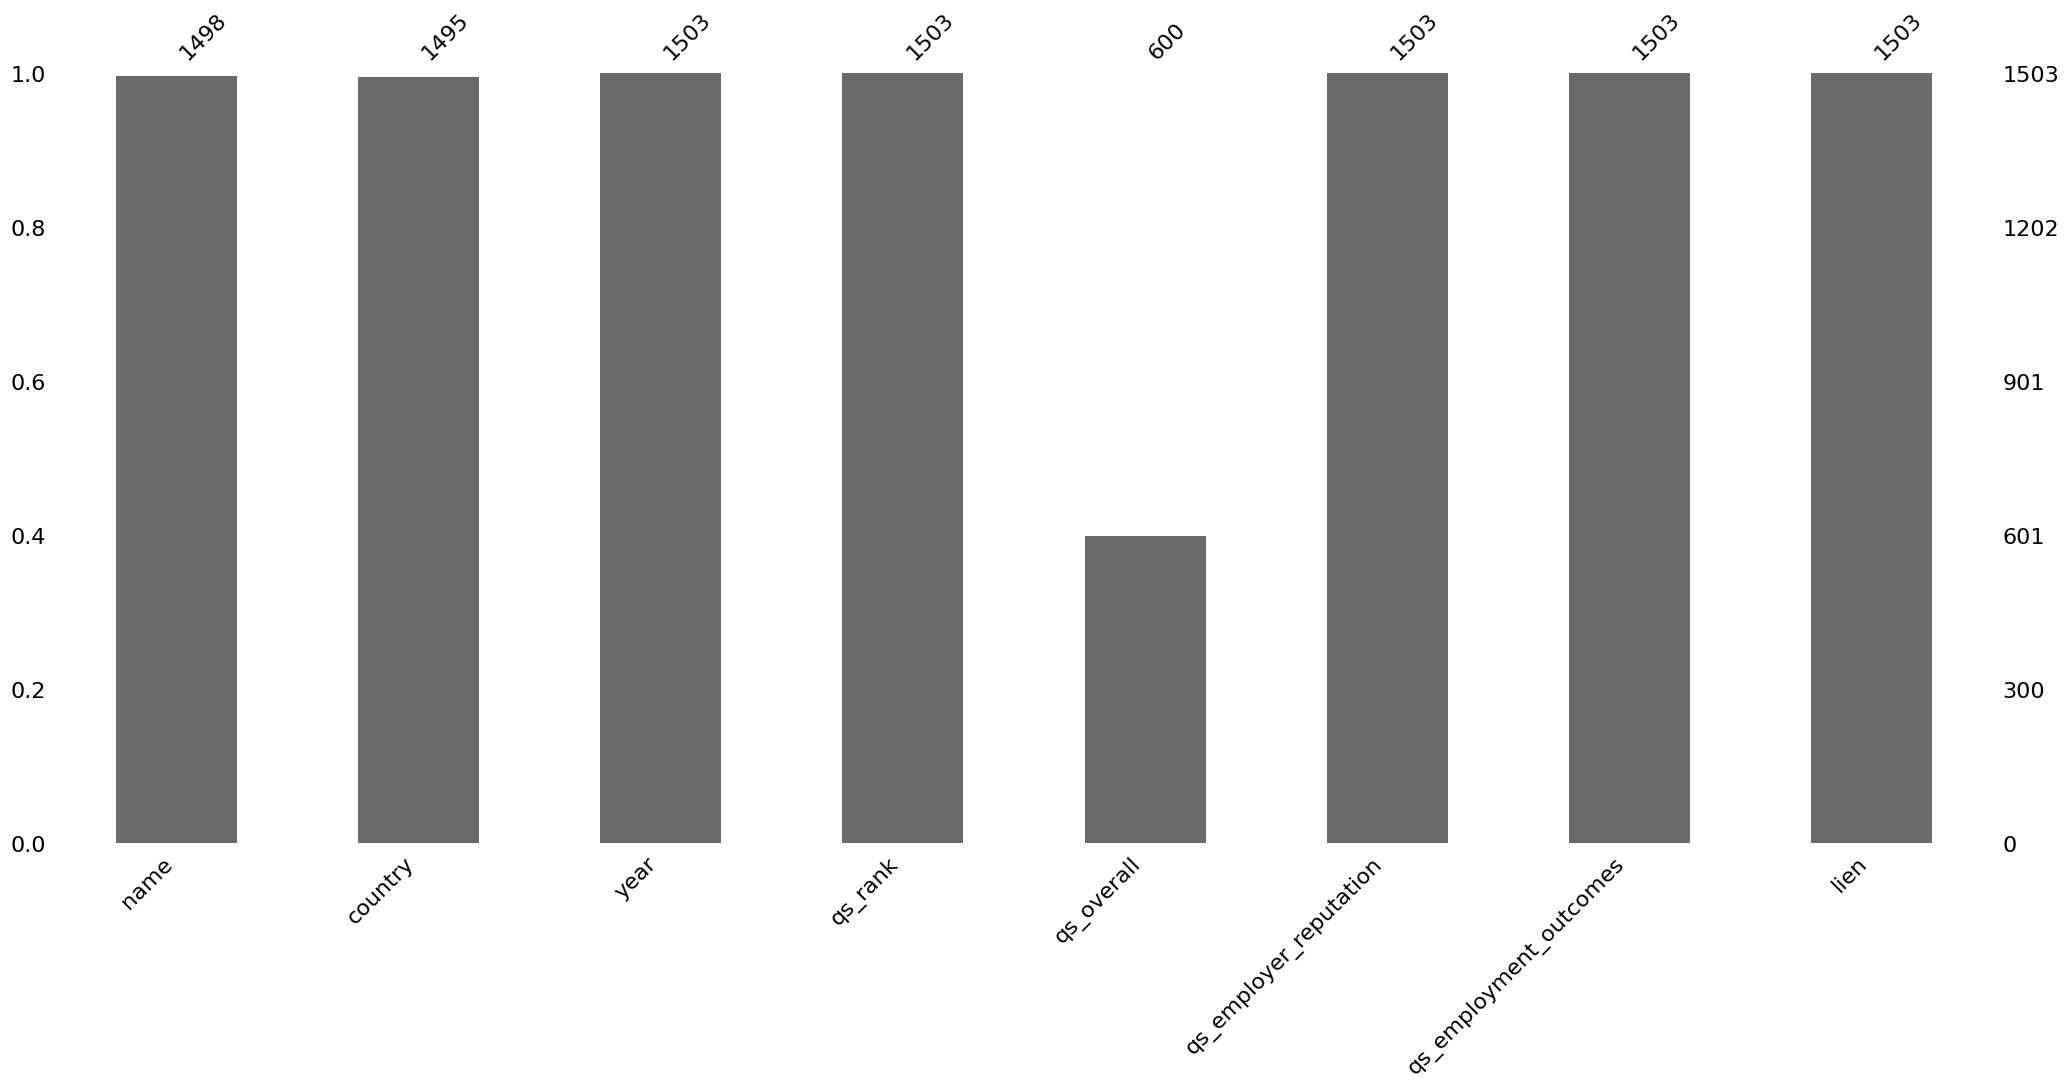


📌 classement_the_disciplines (1).csv
Axes(0.125,0.11;0.775x0.77)


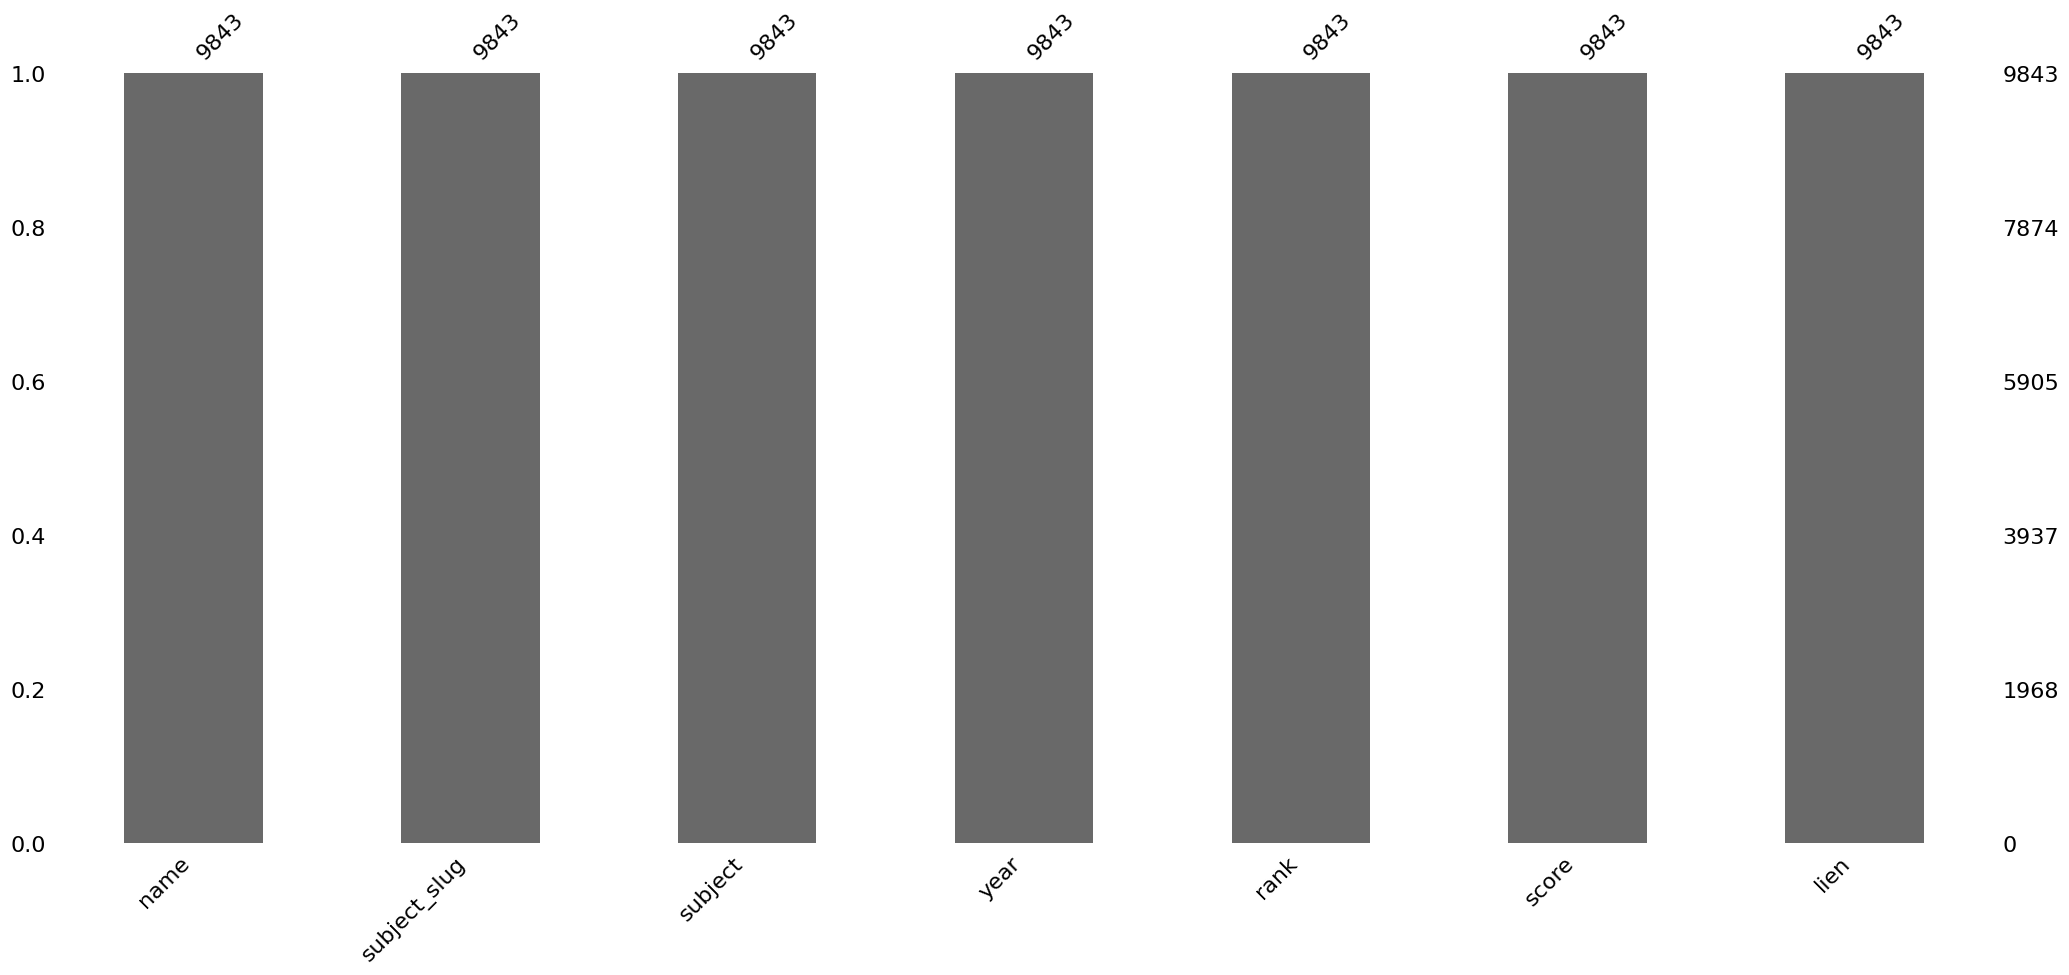


📌 classement_the_impact_odd (1).csv
Axes(0.125,0.11;0.775x0.77)


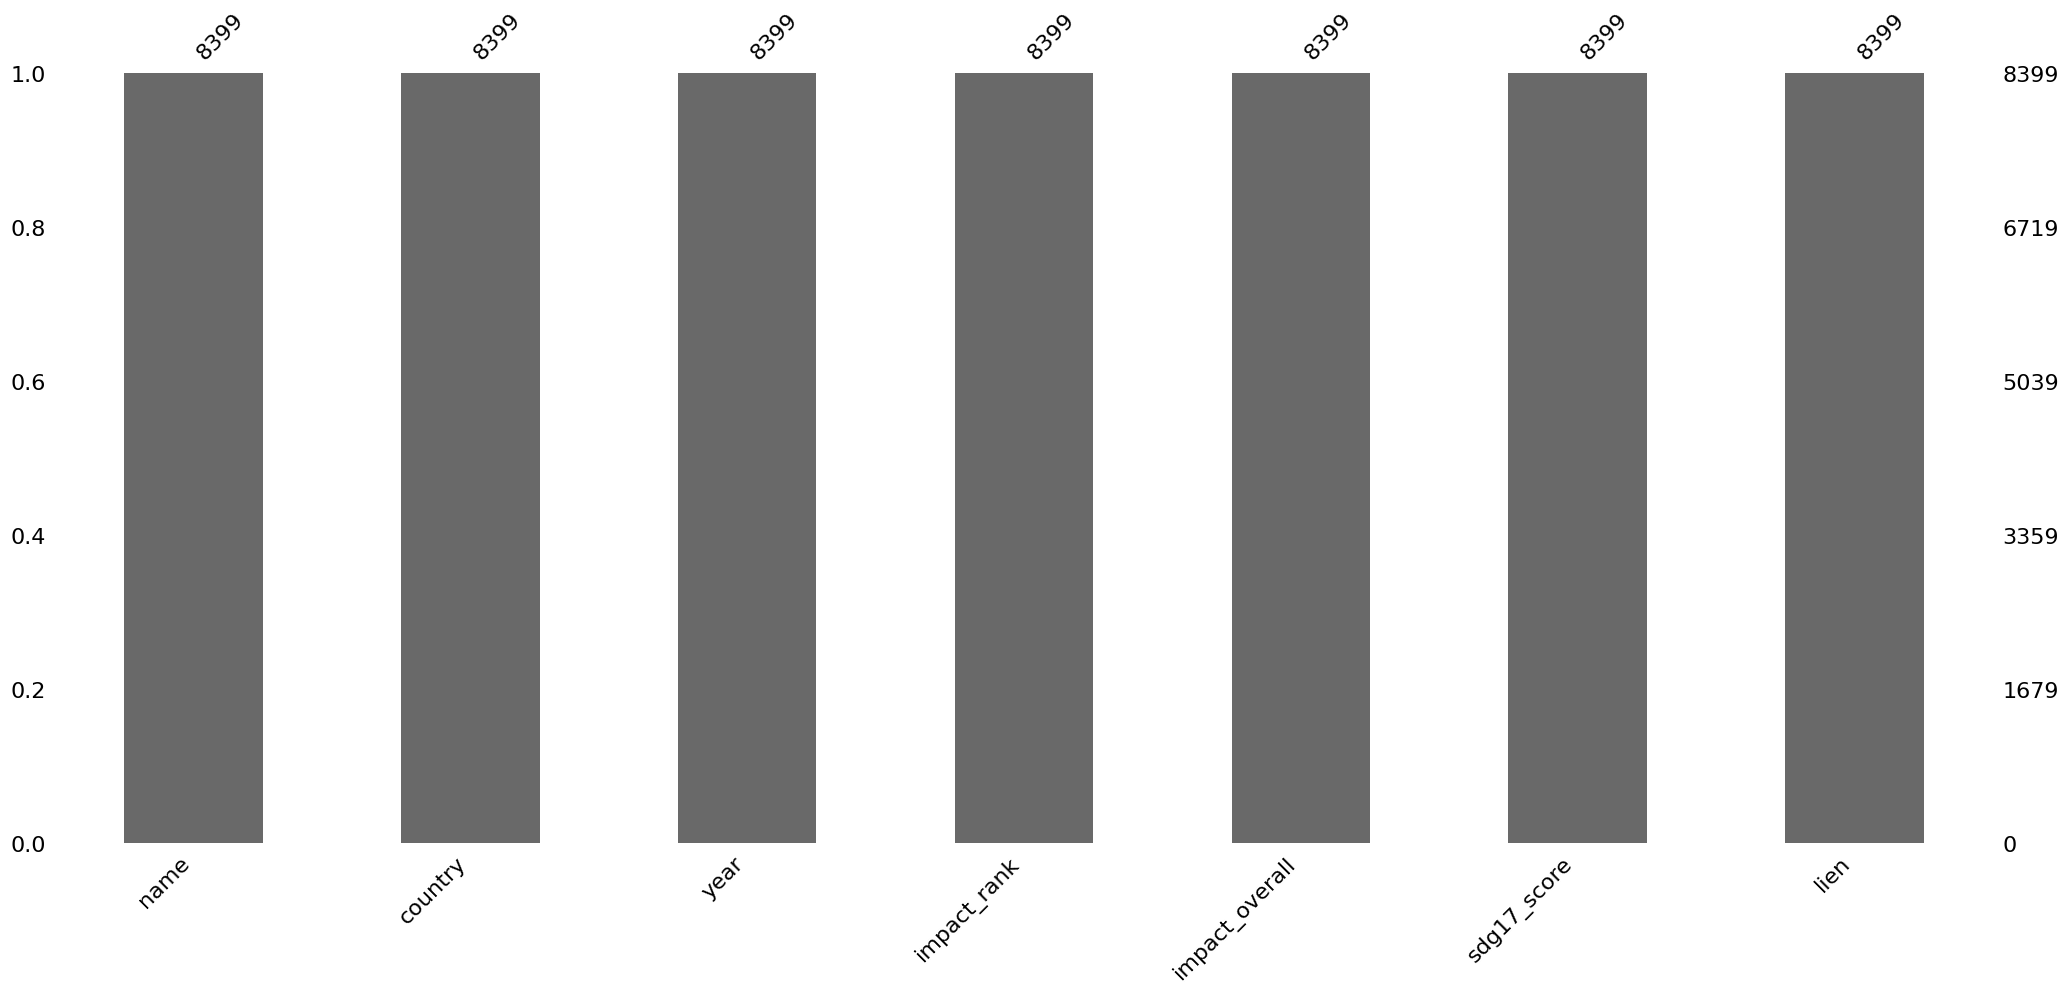


📌 classement_the_monde (1).csv
Axes(0.125,0.11;0.775x0.77)


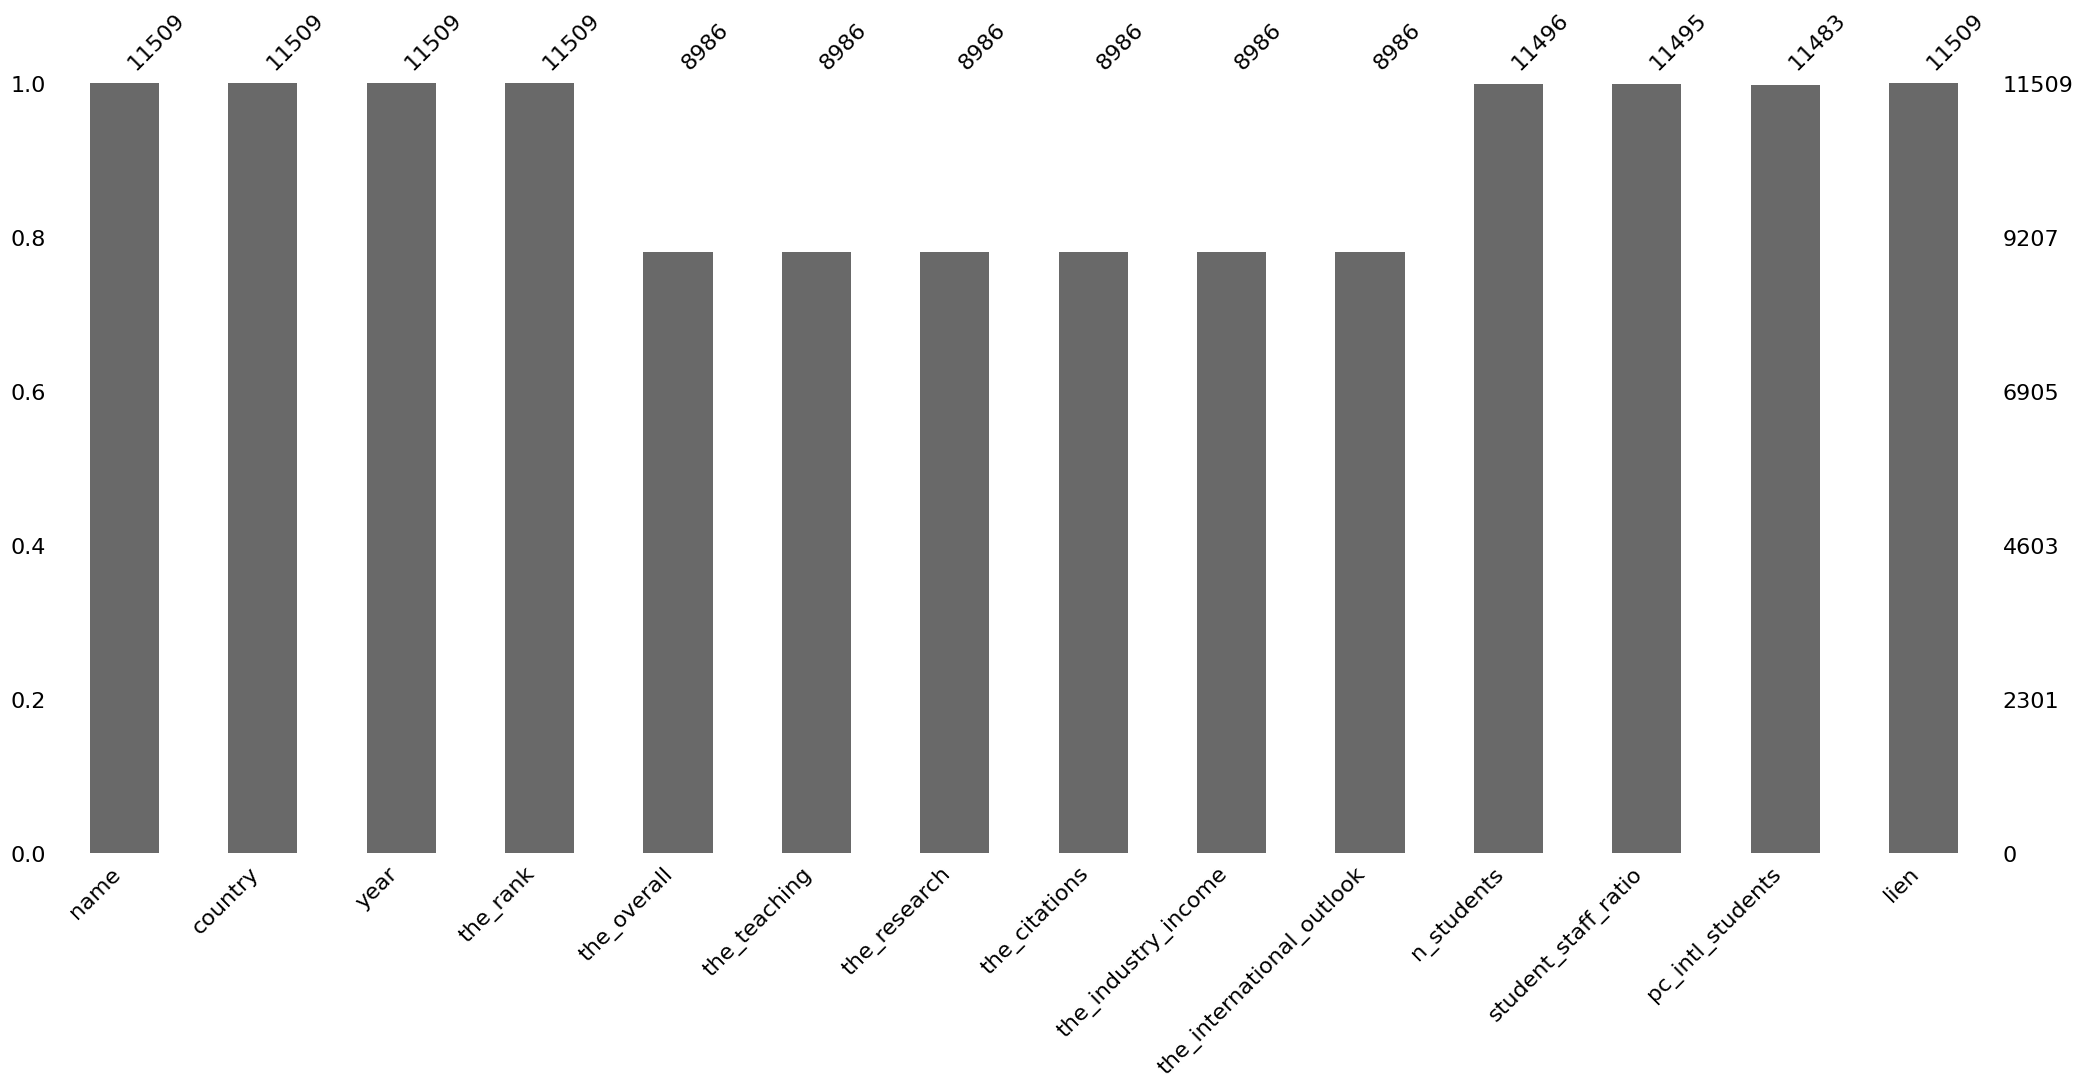


📌 controle_qualite (1).csv
Axes(0.125,0.11;0.775x0.77)


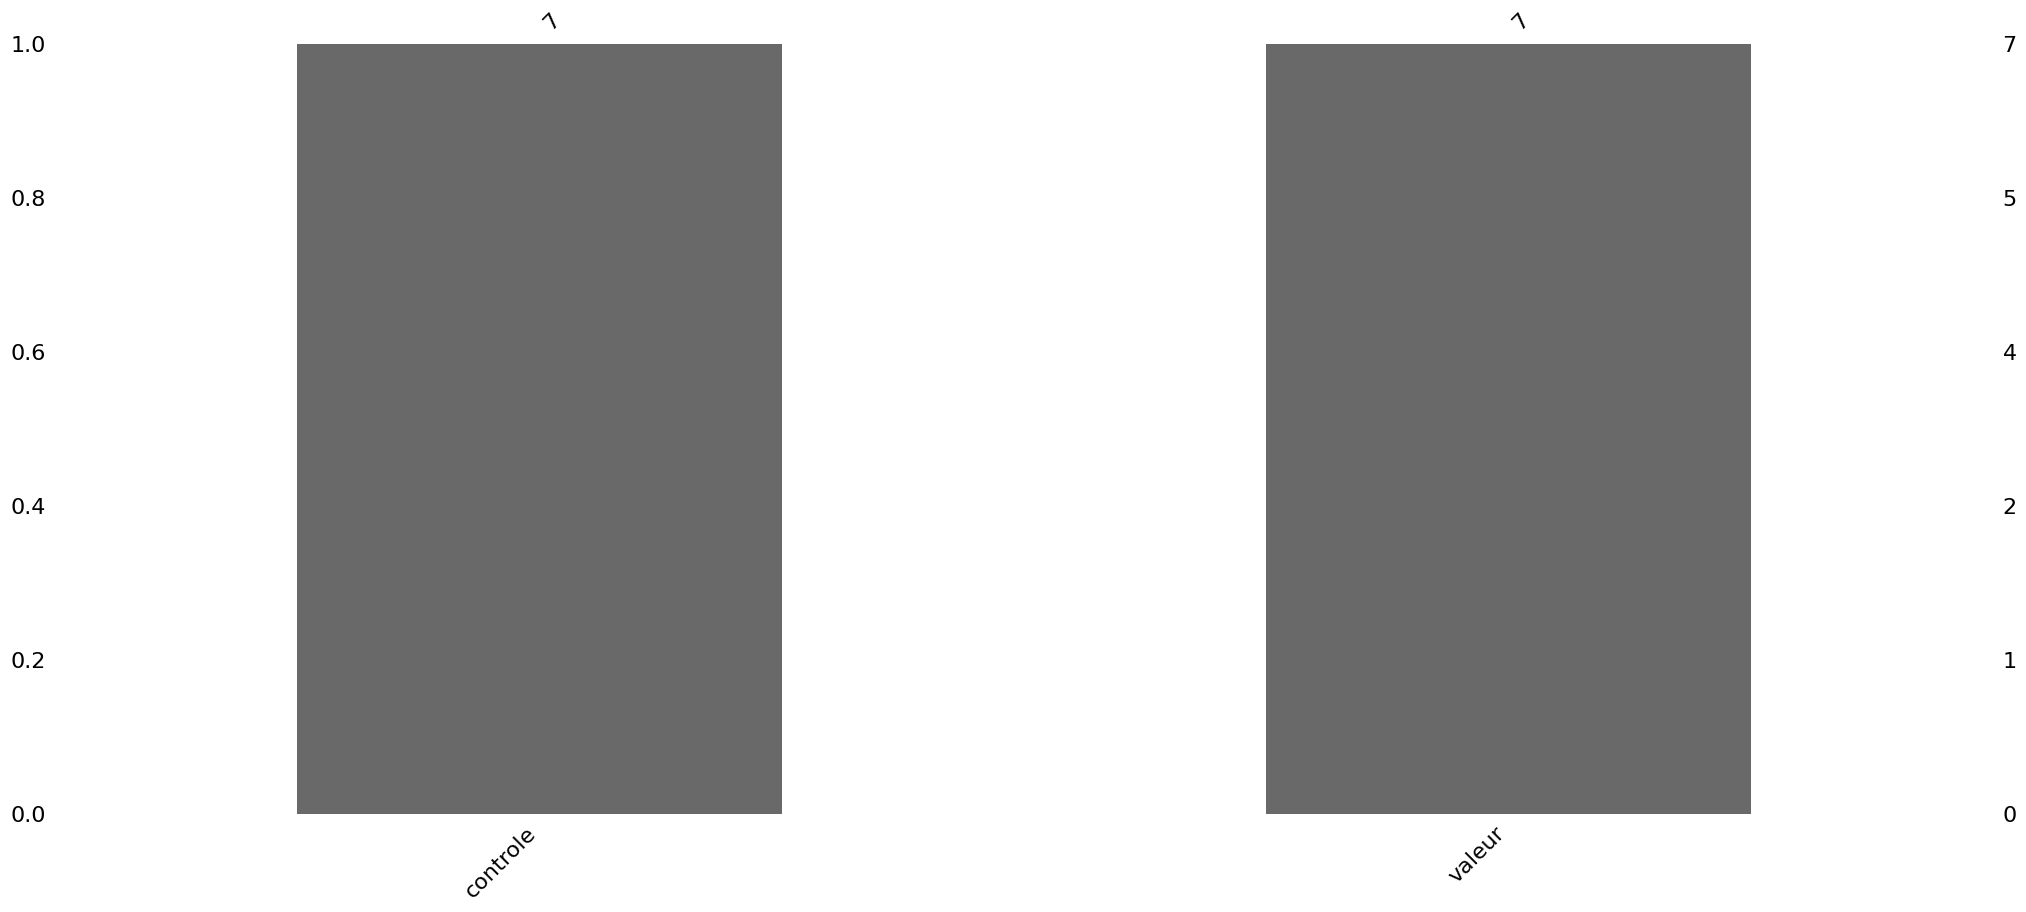


📌 disciplines_par_universite (1).csv
Axes(0.125,0.11;0.775x0.77)


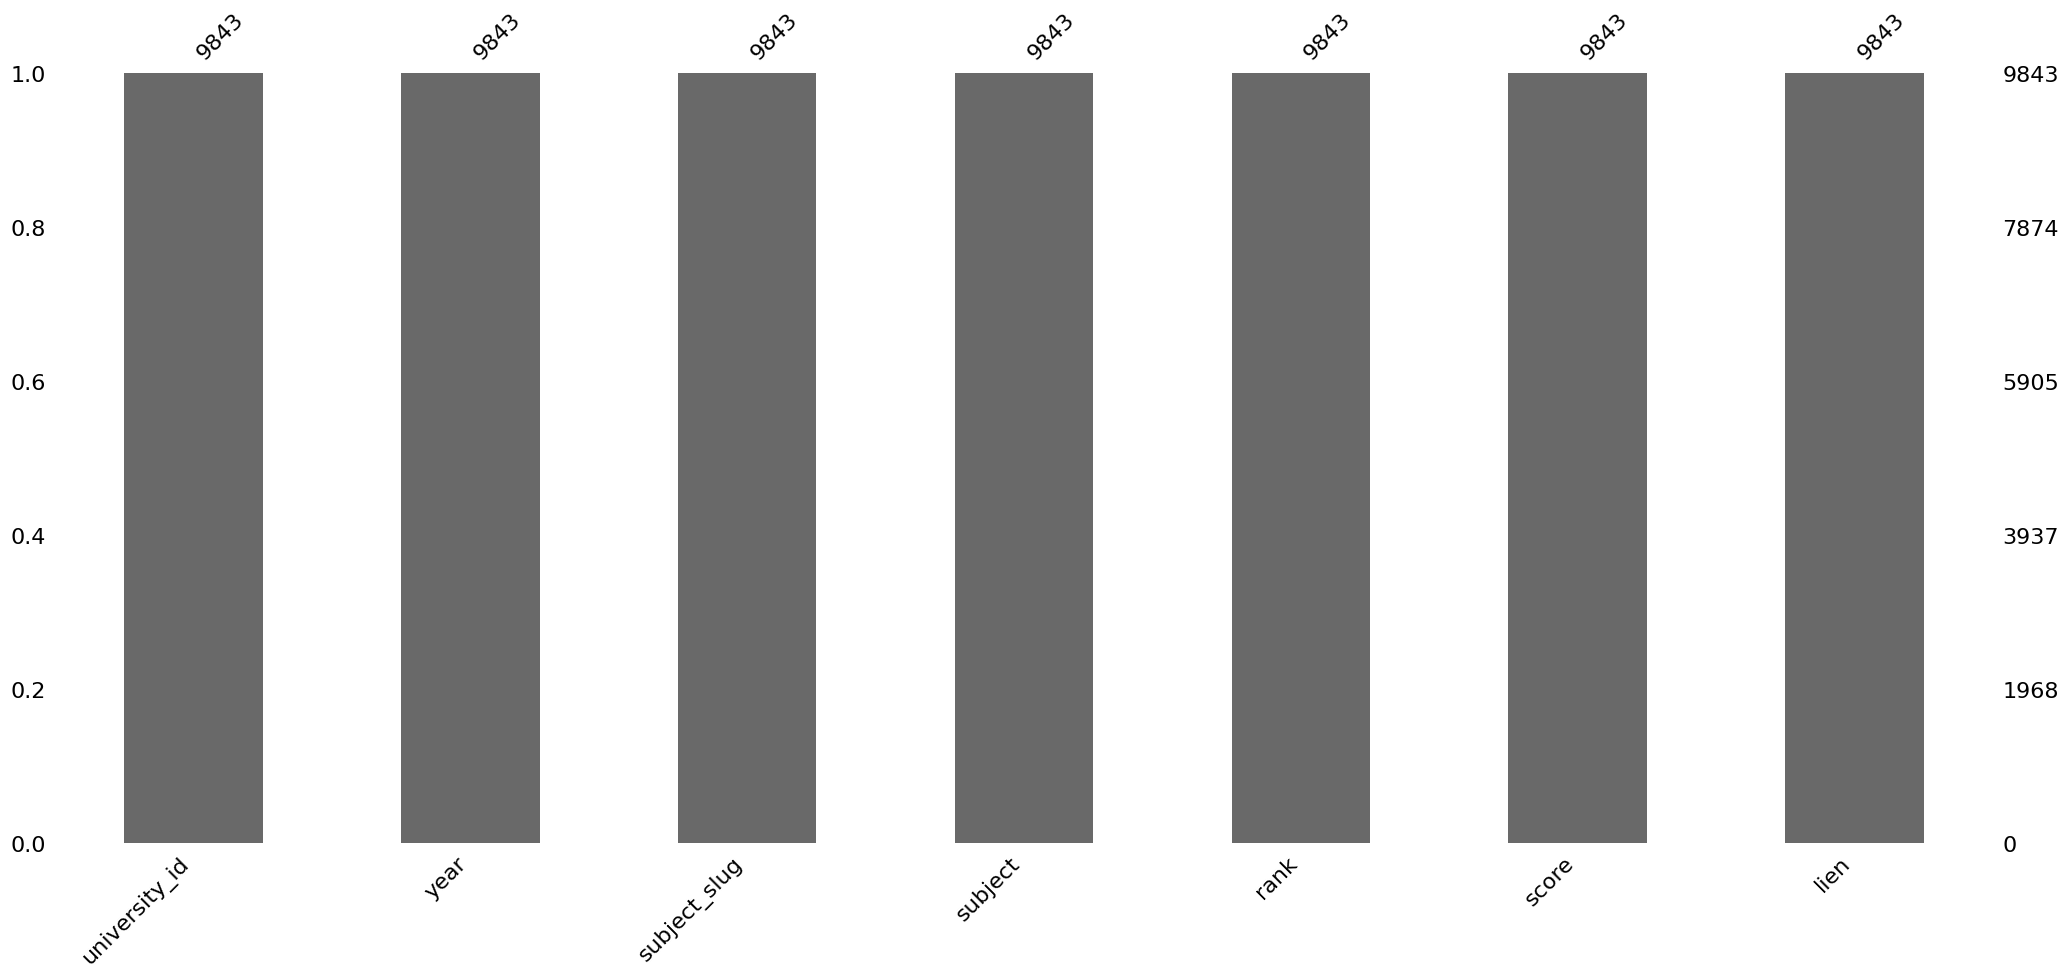


📌 donnees_consolidees (1).csv
Axes(0.125,0.11;0.775x0.77)


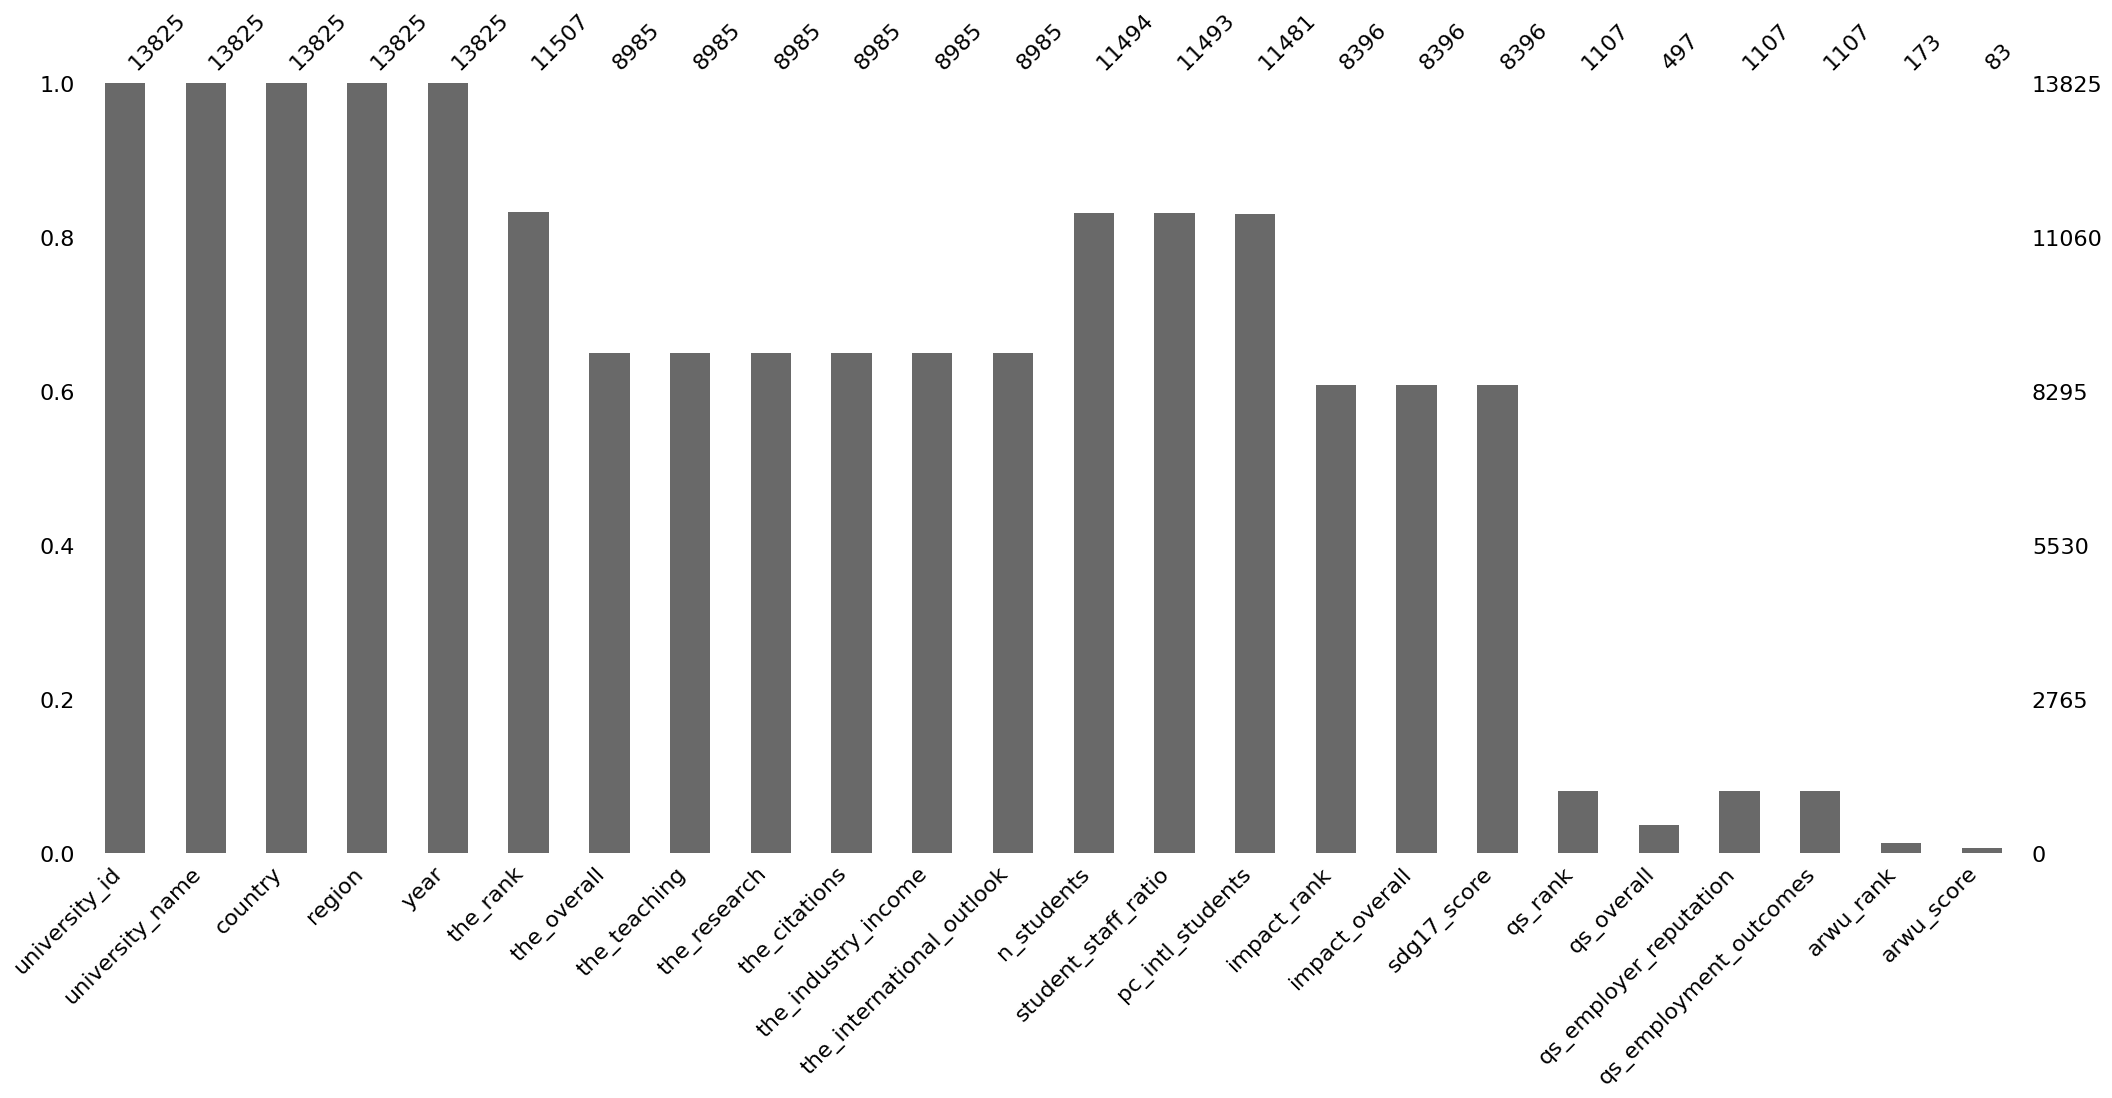


📌 donnees_durabilite (1).xlsx
Axes(0.125,0.11;0.775x0.77)


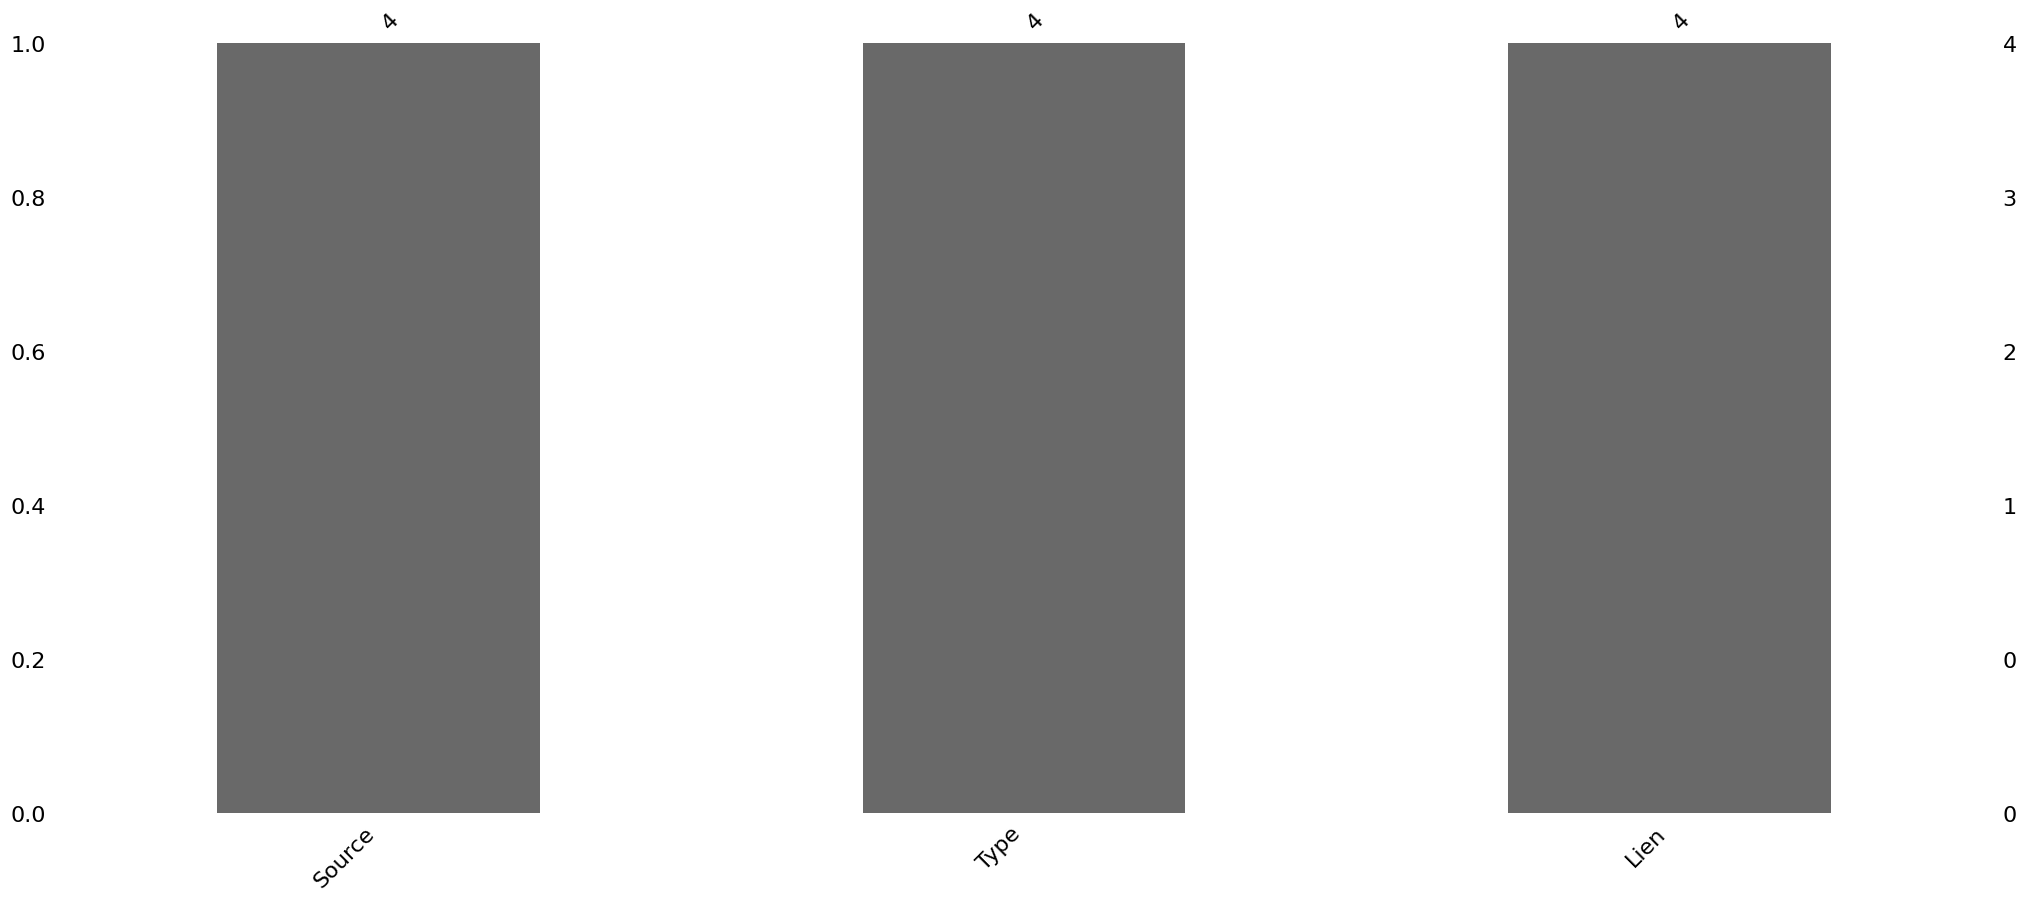


📌 rapports_annuels (1).csv
Axes(0.125,0.11;0.775x0.77)


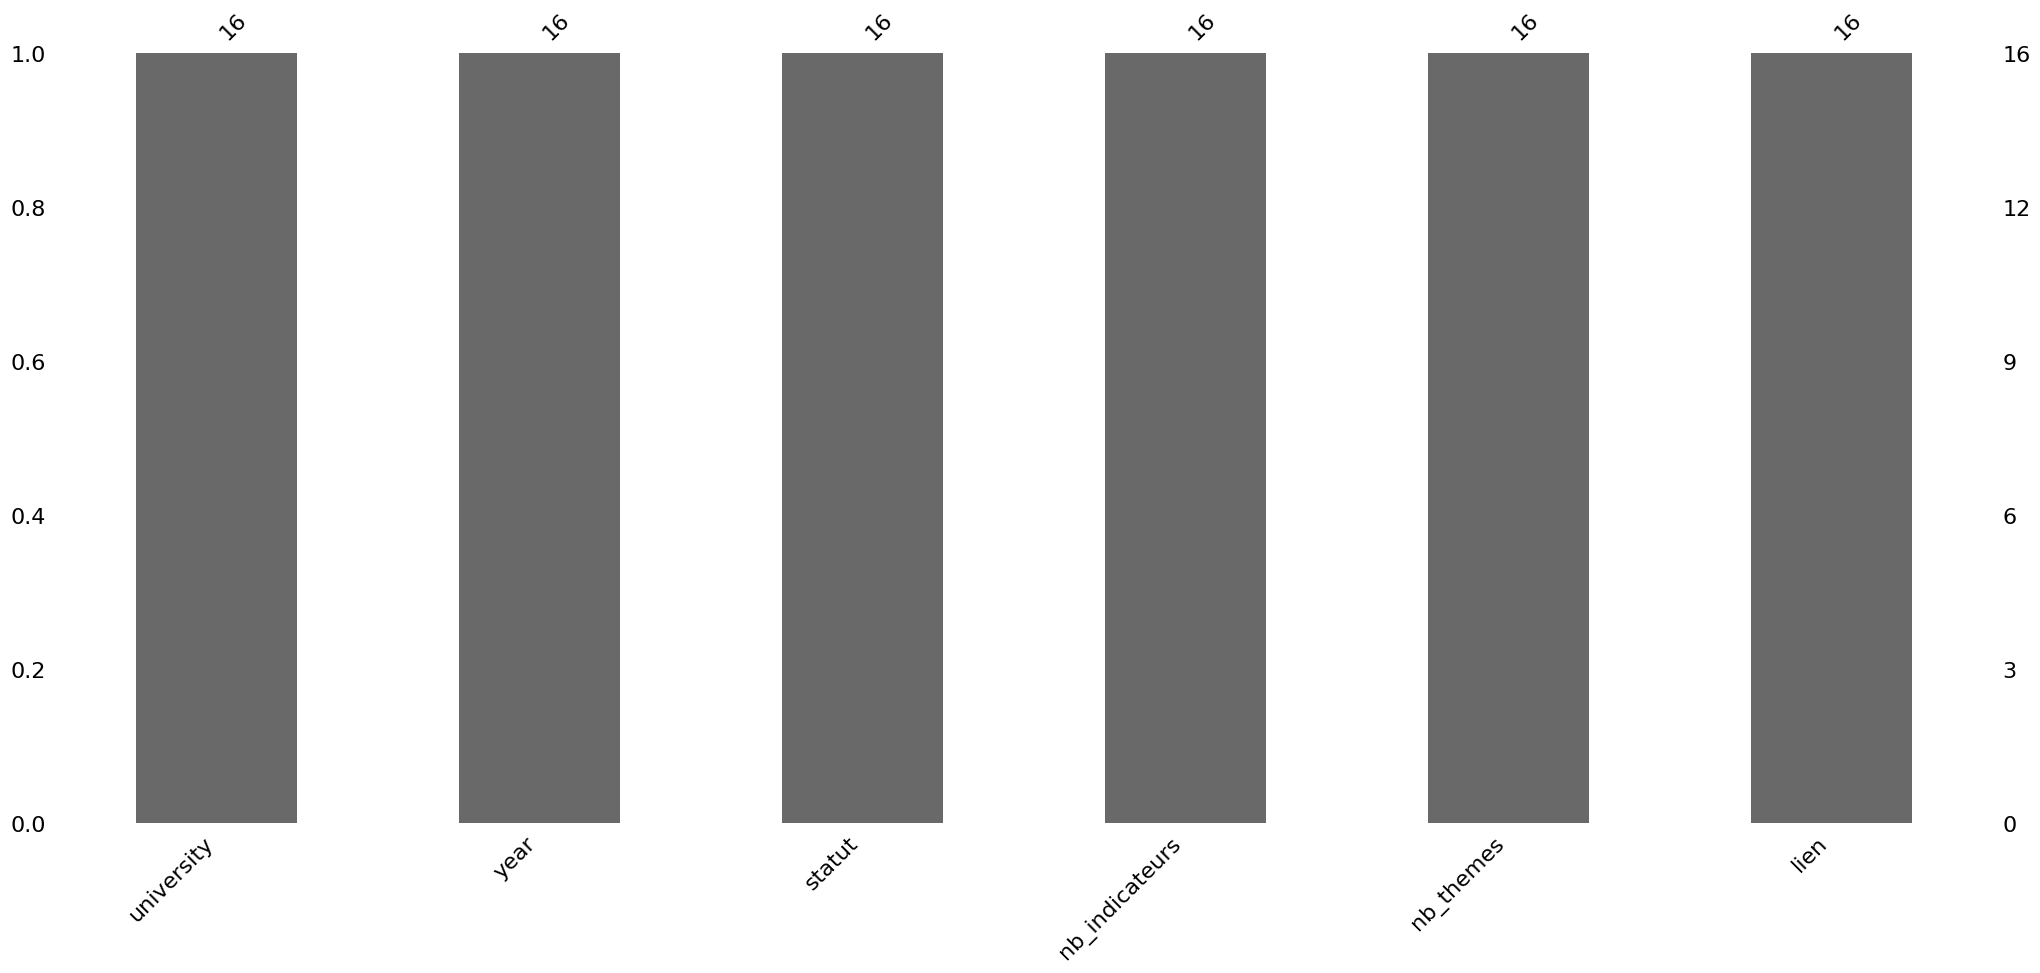


📌 rapports_annuels_details (1).json
Axes(0.125,0.11;0.775x0.77)


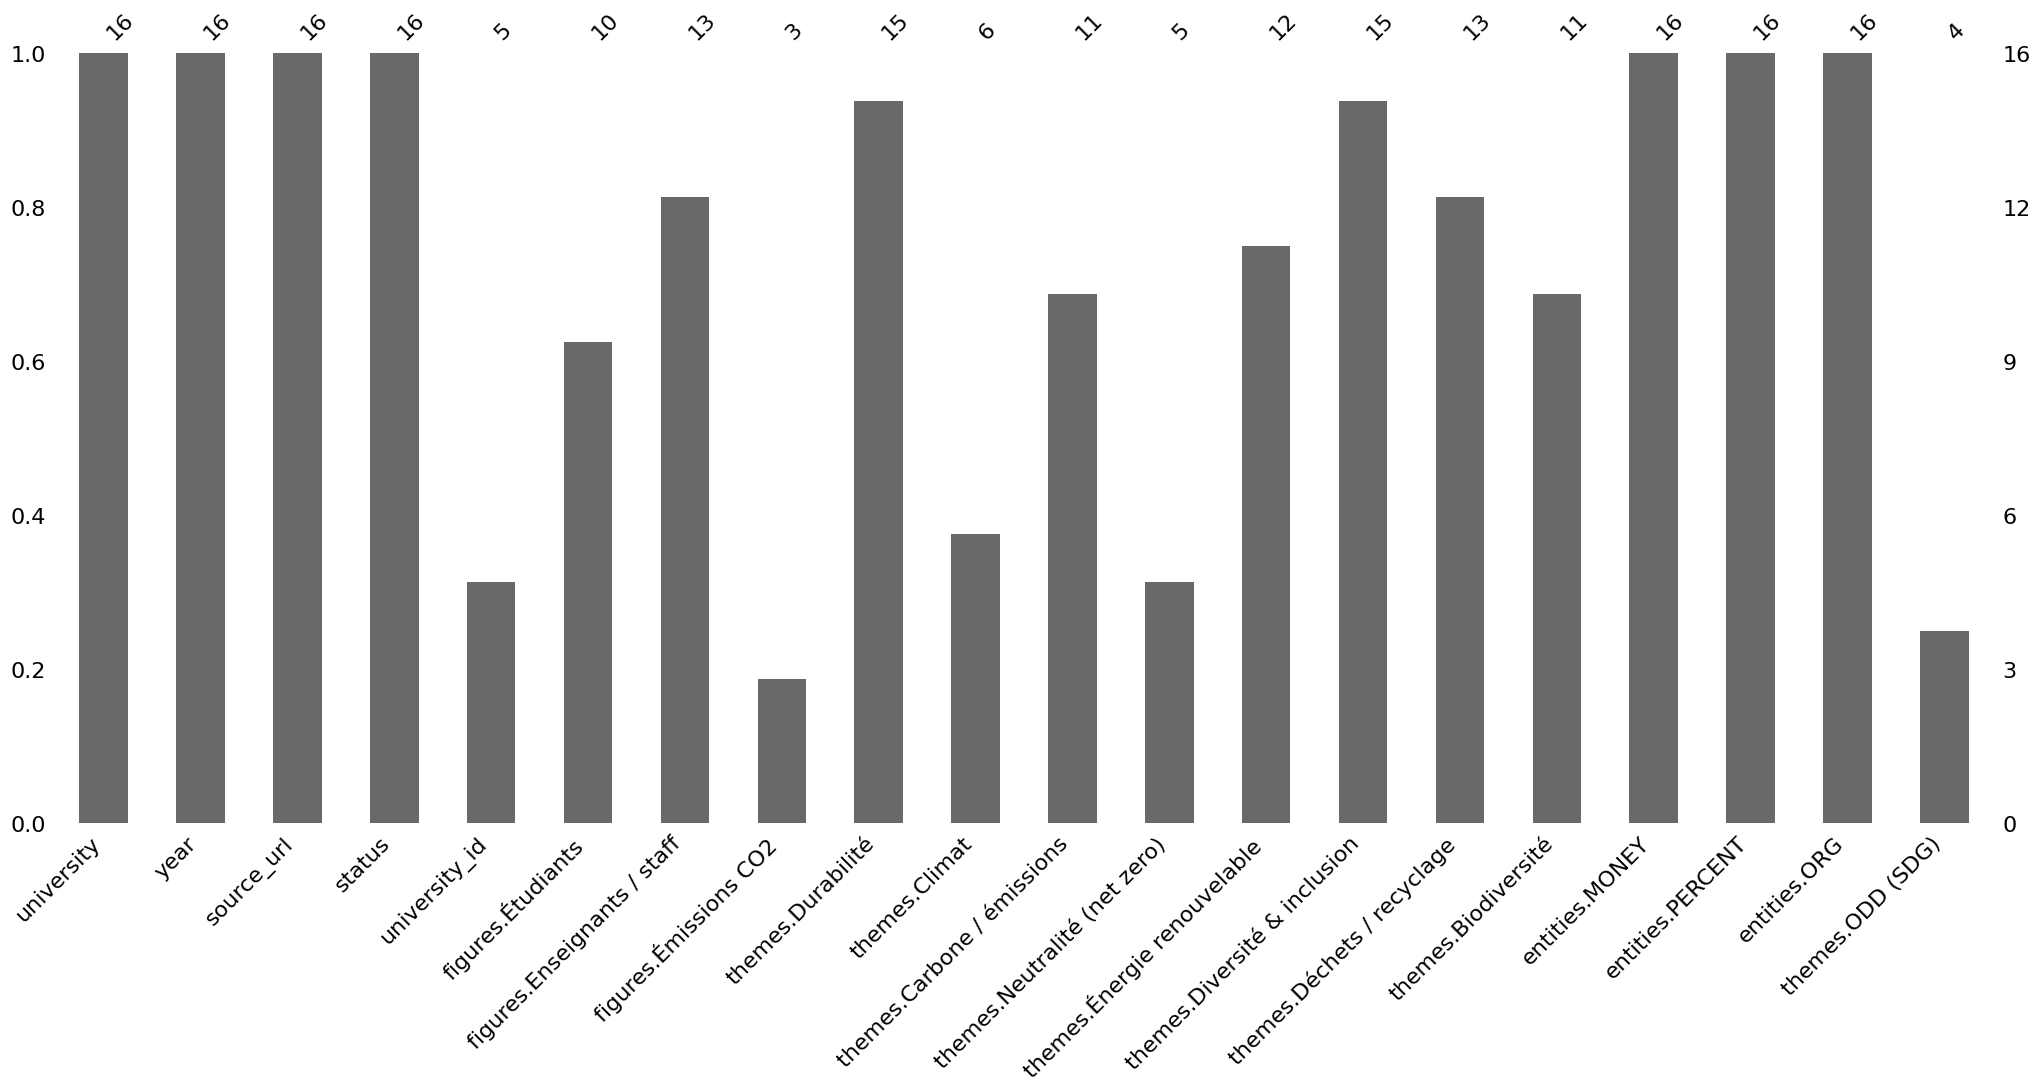


📌 universites (1).csv
Axes(0.125,0.11;0.775x0.77)


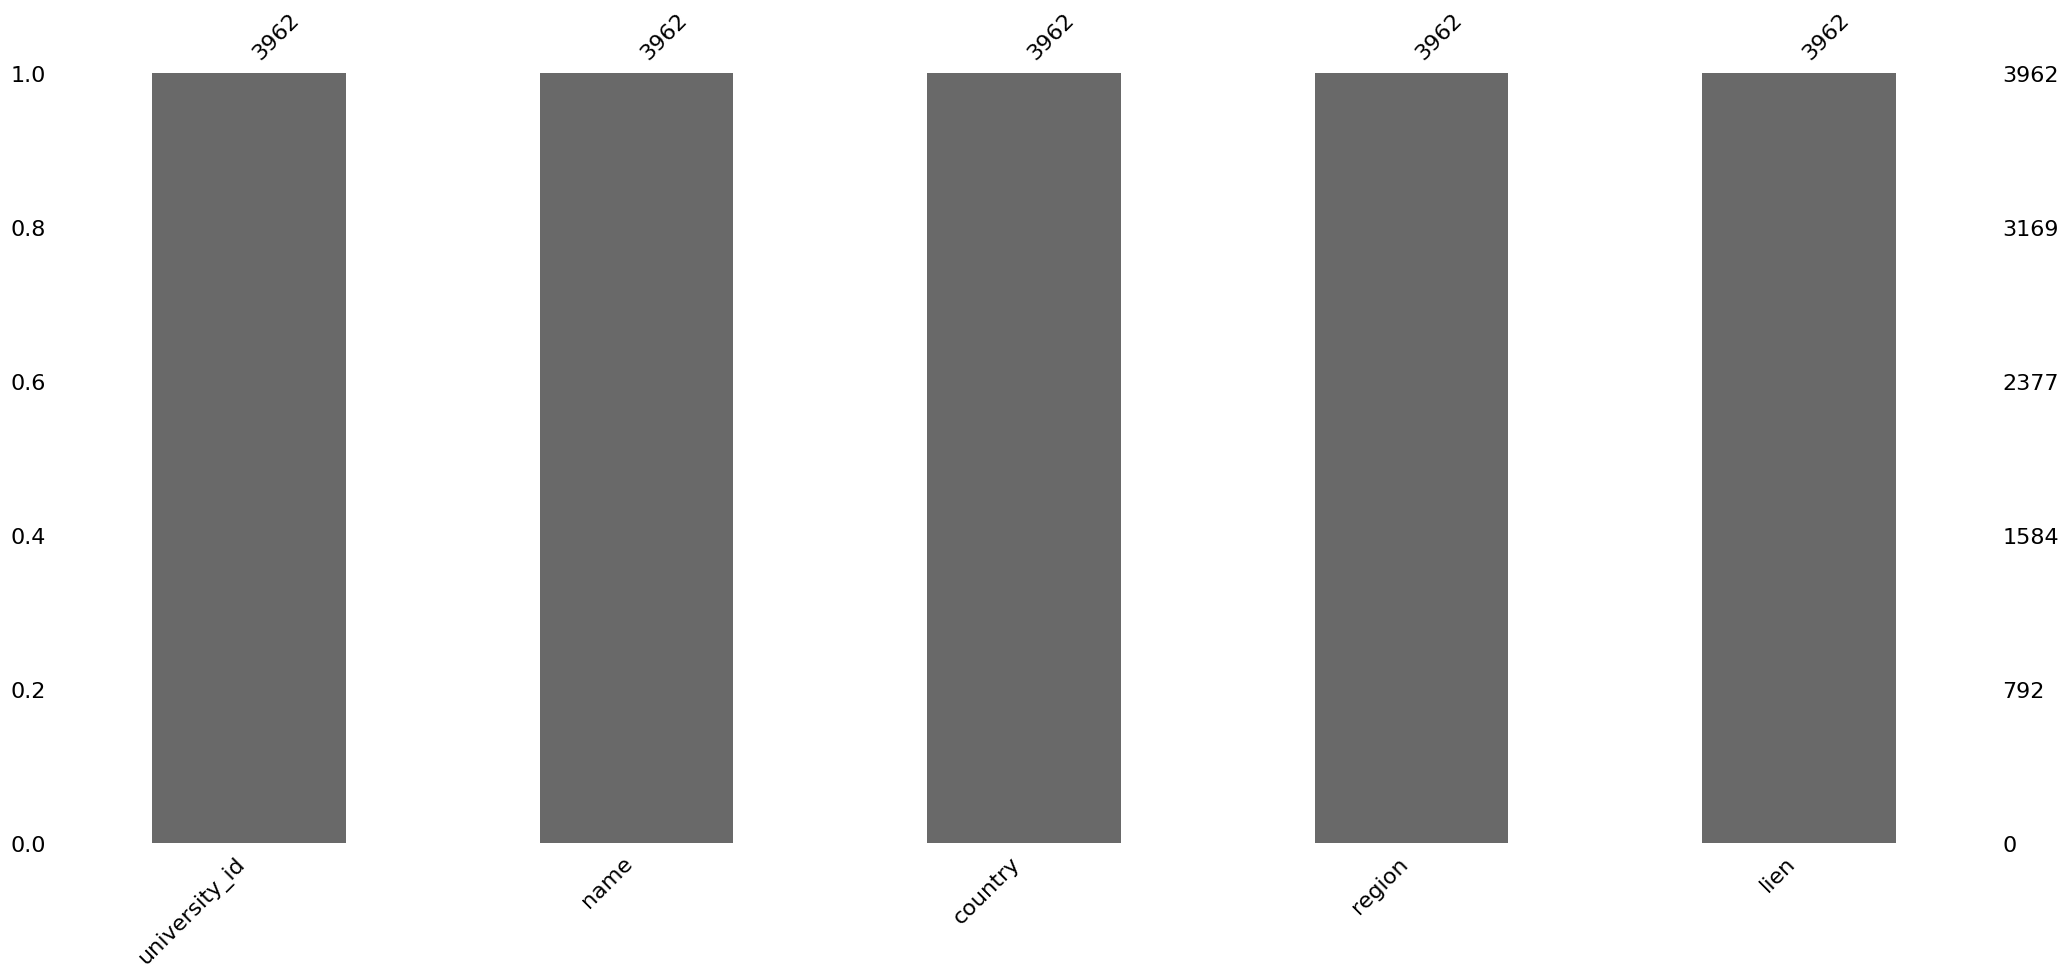

In [ ]:
# Parcourir tous les DataFrames
for name, dataframe in dfs.items():
    print(f"\n📌 {name}")
    print(msno.bar(dataframe))
    plt.show()

In [ ]:
for filename, df in dfs.items():

    print("\n" + "="*60)
    print(f"📁 {filename}")
    print("="*60)

    missing_values = df.isnull().sum()
    missing_percent = (missing_values / len(df)) * 100

    missing_table = pd.DataFrame({
        'Missing Values': missing_values,
        'Percentage': missing_percent
    })

    print(missing_table)


📁 classement_arwu_shanghai (1).csv
            Missing Values  Percentage
name                     0    0.000000
country                  0    0.000000
year                     0    0.000000
arwu_rank                0    0.000000
arwu_score             110   52.380952
lien                     0    0.000000

📁 classement_qs_monde (1).csv
                        Missing Values  Percentage
name                                 5    0.332668
country                              8    0.532269
year                                 0    0.000000
qs_rank                              0    0.000000
qs_overall                         903   60.079840
qs_employer_reputation               0    0.000000
qs_employment_outcomes               0    0.000000
lien                                 0    0.000000

📁 classement_the_disciplines (1).csv
              Missing Values  Percentage
name                       0         0.0
subject_slug               0         0.0
subject                    0         0.0

# Imputation par la médiane, la moyenne et le mode

L'imputation par la moyenne, la médiane et le mode sont des méthodes simples pour remplacer les valeurs manquantes dans une variable.

L'imputation par la moyenne consiste à remplacer les valeurs manquantes par la moyenne des valeurs non manquantes dans la variable. Cette méthode est utile pour les variables continues et symétriques.

L'imputation par la médiane consiste à remplacer les valeurs manquantes par la médiane des valeurs non manquantes dans la variable. Cette méthode est utile pour les variables continues qui ont une distribution asymétrique ou pour les variables ordinales.

L'imputation par le mode consiste à remplacer les valeurs manquantes par le mode, c'est-à-dire la valeur la plus fréquente, dans la variable. Cette méthode est utile pour les variables catégorielles ou nominales.

Ces méthodes sont simples à mettre en œuvre et peuvent être efficaces lorsque les données manquantes sont MCAR (Missing Completely At Random), c'est-à-dire que les valeurs manquantes sont indépendantes des autres variables. Toutefois, elles peuvent introduire un biais dans les données si les valeurs manquantes sont liées à d'autres variables dans les données.

## Imputation par la moyenne

In [ ]:
from sklearn.impute import SimpleImputer

for filename, df in dfs.items():

    # Sélectionner toutes les colonnes numériques
    numeric_columns = df.select_dtypes(include='number').columns

    if len(numeric_columns) > 0:

        imputer_mean = SimpleImputer(strategy='mean')

        df[numeric_columns] = imputer_mean.fit_transform(df[numeric_columns])

    print(f"✅ Moyenne appliquée aux colonnes numériques de : {filename}")

✅ Moyenne appliquée aux colonnes numériques de : classement_arwu_shanghai (1).csv
✅ Moyenne appliquée aux colonnes numériques de : classement_qs_monde (1).csv
✅ Moyenne appliquée aux colonnes numériques de : classement_the_disciplines (1).csv
✅ Moyenne appliquée aux colonnes numériques de : classement_the_impact_odd (1).csv
✅ Moyenne appliquée aux colonnes numériques de : classement_the_monde (1).csv
✅ Moyenne appliquée aux colonnes numériques de : controle_qualite (1).csv
✅ Moyenne appliquée aux colonnes numériques de : disciplines_par_universite (1).csv
✅ Moyenne appliquée aux colonnes numériques de : donnees_consolidees (1).csv
✅ Moyenne appliquée aux colonnes numériques de : donnees_durabilite (1).xlsx
✅ Moyenne appliquée aux colonnes numériques de : rapports_annuels (1).csv
✅ Moyenne appliquée aux colonnes numériques de : rapports_annuels_details (1).json
✅ Moyenne appliquée aux colonnes numériques de : universites (1).csv


In [ ]:
for filename, df in dfs.items():
    print(f"\n📁 {filename}")
    print(df.isnull().mean())


📁 classement_arwu_shanghai (1).csv
name          0.0
country       0.0
year          0.0
arwu_rank     0.0
arwu_score    0.0
lien          0.0
dtype: float64

📁 classement_qs_monde (1).csv
name                      0.003327
country                   0.005323
year                      0.000000
qs_rank                   0.000000
qs_overall                0.000000
qs_employer_reputation    0.000000
qs_employment_outcomes    0.000000
lien                      0.000000
dtype: float64

📁 classement_the_disciplines (1).csv
name            0.0
subject_slug    0.0
subject         0.0
year            0.0
rank            0.0
score           0.0
lien            0.0
dtype: float64

📁 classement_the_impact_odd (1).csv
name              0.0
country           0.0
year              0.0
impact_rank       0.0
impact_overall    0.0
sdg17_score       0.0
lien              0.0
dtype: float64

📁 classement_the_monde (1).csv
name                         0.0
country                      0.0
year              

## Imputation par le mode

In [ ]:
for filename, df in dfs.items():

    for col in df.columns:

        # Valeurs manquantes
        if df[col].isnull().any():

            if len(df[col]) == 0:
                continue

            first_value = df[col].iloc[0]

            # ─── Liste ───────────────────────────────────────────────────────
            if isinstance(first_value, list):
                df[col] = df[col].apply(
                    lambda x: [] if pd.isna(x) else x
                )

            # ─── Dictionnaire ───────────────────────────────────────────────
            elif isinstance(first_value, dict):
                df[col] = df[col].apply(
                    lambda x: {} if pd.isna(x) else x
                )

            # ─── Colonnes object classiques → mode ──────────────────────────
            elif df[col].dtype == 'object':
                mode = df[col].mode(dropna=True)

                if not mode.empty:
                    df[col] = df[col].fillna(mode.iloc[0])

    print(f"✅ Traitement terminé : {filename}")

✅ Traitement terminé : classement_arwu_shanghai (1).csv
✅ Traitement terminé : classement_qs_monde (1).csv
✅ Traitement terminé : classement_the_disciplines (1).csv
✅ Traitement terminé : classement_the_impact_odd (1).csv
✅ Traitement terminé : classement_the_monde (1).csv
✅ Traitement terminé : controle_qualite (1).csv
✅ Traitement terminé : disciplines_par_universite (1).csv
✅ Traitement terminé : donnees_consolidees (1).csv
✅ Traitement terminé : donnees_durabilite (1).xlsx
✅ Traitement terminé : rapports_annuels (1).csv
✅ Traitement terminé : rapports_annuels_details (1).json
✅ Traitement terminé : universites (1).csv


In [ ]:
# Vérifier les valeurs manquantes après traitement
for filename, df in dfs.items():

    print("\n" + "="*60)
    print(f"📁 {filename}")
    print("="*60)

    missing_values = df.isnull().sum()

    print("\nMissing Values After Treatment:\n")
    print(missing_values)


📁 classement_arwu_shanghai (1).csv

Missing Values After Treatment:

name          0
country       0
year          0
arwu_rank     0
arwu_score    0
lien          0
dtype: int64

📁 classement_qs_monde (1).csv

Missing Values After Treatment:

name                      0
country                   0
year                      0
qs_rank                   0
qs_overall                0
qs_employer_reputation    0
qs_employment_outcomes    0
lien                      0
dtype: int64

📁 classement_the_disciplines (1).csv

Missing Values After Treatment:

name            0
subject_slug    0
subject         0
year            0
rank            0
score           0
lien            0
dtype: int64

📁 classement_the_impact_odd (1).csv

Missing Values After Treatment:

name              0
country           0
year              0
impact_rank       0
impact_overall    0
sdg17_score       0
lien              0
dtype: int64

📁 classement_the_monde (1).csv

Missing Values After Treatment:

name              

In [ ]:
columns_to_drop = [
    'figures.Étudiants',
    'figures.Enseignants / staff',
    'figures.Émissions CO2'
]

for filename, df in dfs.items():
    df.drop(columns=columns_to_drop, errors='ignore', inplace=True)
    print(f"✅ Colonnes supprimées de : {filename}")

✅ Colonnes supprimées de : classement_arwu_shanghai (1).csv
✅ Colonnes supprimées de : classement_qs_monde (1).csv
✅ Colonnes supprimées de : classement_the_disciplines (1).csv
✅ Colonnes supprimées de : classement_the_impact_odd (1).csv
✅ Colonnes supprimées de : classement_the_monde (1).csv
✅ Colonnes supprimées de : controle_qualite (1).csv
✅ Colonnes supprimées de : disciplines_par_universite (1).csv
✅ Colonnes supprimées de : donnees_consolidees (1).csv
✅ Colonnes supprimées de : donnees_durabilite (1).xlsx
✅ Colonnes supprimées de : rapports_annuels (1).csv
✅ Colonnes supprimées de : rapports_annuels_details (1).json
✅ Colonnes supprimées de : universites (1).csv


In [ ]:
for filename, df in dfs.items():
    print(f"\n📁 {filename}")
    print(df.columns.tolist())


📁 classement_arwu_shanghai (1).csv
['name', 'country', 'year', 'arwu_rank', 'arwu_score', 'lien']

📁 classement_qs_monde (1).csv
['name', 'country', 'year', 'qs_rank', 'qs_overall', 'qs_employer_reputation', 'qs_employment_outcomes', 'lien']

📁 classement_the_disciplines (1).csv
['name', 'subject_slug', 'subject', 'year', 'rank', 'score', 'lien']

📁 classement_the_impact_odd (1).csv
['name', 'country', 'year', 'impact_rank', 'impact_overall', 'sdg17_score', 'lien']

📁 classement_the_monde (1).csv
['name', 'country', 'year', 'the_rank', 'the_overall', 'the_teaching', 'the_research', 'the_citations', 'the_industry_income', 'the_international_outlook', 'n_students', 'student_staff_ratio', 'pc_intl_students', 'lien']

📁 controle_qualite (1).csv
['controle', 'valeur']

📁 disciplines_par_universite (1).csv
['university_id', 'year', 'subject_slug', 'subject', 'rank', 'score', 'lien']

📁 donnees_consolidees (1).csv
['university_id', 'university_name', 'country', 'region', 'year', 'the_rank', 

In [ ]:
import os
import shutil

# Créer le dossier dans Colab
os.makedirs("data_nettoye", exist_ok=True)

# Exporter les DataFrames nettoyés
for filename, df in dfs.items():
    name = os.path.splitext(filename)[0]
    output_path = os.path.join("data_nettoye", name + ".xlsx")
    df.to_excel(output_path, index=False)

# Créer le ZIP
shutil.make_archive("data_nettoye", "zip", "data_nettoye")

print("✅ Fichiers nettoyés prêts à être téléchargés.")

✅ Fichiers nettoyés prêts à être téléchargés.


In [ ]:
from google.colab import files

files.download("data_nettoye.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>